# Notebook 1 — Preprocessing NLP, NER Cyber & Base Neo4j

**Responsable :** Walid · **Chapitre 1** (NLP fondamental, vectorisation & graphes) · **TDSP étape 2** (*Data Acquisition & Understanding*)
**Livrables (Jalon 1)** : corpus prétraité, fichier JSON des entités cyber, graphe STIX 2.1, scripts Cypher Neo4j.

| Besoin SOC | Réponse de ce notebook | Section |
| --- | --- | --- |
| Comprendre le corpus avant tout modèle | Nettoyage tracé, statistiques, thèmes LDA, graphe de co-occurrence NPMI | 2 → 9 |
| Choisir une représentation du texte | Comparaison mesurée **TF-IDF vs Word2Vec vs GloVe vs SBERT** | 10 – 11 |
| Extraire IP, CVE, malwares, logiciels, cibles | NER à règles (STIX) puis **fine-tuning SecBERT** évalué sur entités jamais vues | 12 |
| Relier menaces, vecteurs et cibles | Ontologie **STIX 2.1 / MITRE ATT&CK**, graphe, import **Neo4j** (Cypher) | 13 – 14 |
| Alimenter l'équipe | `entities.json`, `knowledge_graph.json`, `rag_documents.jsonl`, thèmes LDA | 15 |

**Données** : `AlicanKiraz0/Cybersecurity-Dataset-v1` (2 411 paires *system / user / assistant*, licence Apache 2.0), révision figée et vérifiée par empreinte SHA-256 (`data/raw/cybersec_v1/provenance.json`).

**Code partagé** : la logique réutilisée par les autres notebooks et le MVP (nettoyage, NER, graphe, export Cypher) vit dans `src/cybersec_nlp/` et est couverte par des tests unitaires ; ce notebook l'exécute, l'explique et la mesure.

> Exécuter **de haut en bas** (*Restart & Run All*). Durée : ~10 min avec GPU (fine-tuning SecBERT ≈ 2 min). Tous les paramètres sont en section 1.

## 1. Configuration et imports

In [1]:
# Initialisation commune à tous les notebooks du projet : racine du dépôt + package partagé
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from cybersec_nlp import config  # chemins et constantes partagés (data/, artifacts/, reports/)

import html
import json
import os
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from gensim import corpora
from gensim.models import CoherenceModel, LdaModel, Word2Vec
from IPython.display import IFrame, display
from pyvis.network import Network
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

from cybersec_nlp.data.loading import clean_dataset, load_raw

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ---------- Paramètres globaux ----------
RANDOM_STATE = 42
TEXT_COLS = ["user", "assistant"]          # la colonne 'system' est supprimée à l'étape 4

# Nettoyage
USER_MIN_WORDS = 3
ASSISTANT_MIN_WORDS = 10

# LDA
K_RANGE = range(4, 13)                     # valeurs de k testées pour la cohérence C_V
LDA_PASSES = 15                            # même valeur pour la recherche de k et le modèle final
K_OVERRIDE = None    # None = k qui maximise C_V (section 8.1) ; un entier (ex. 6) force la valeur

# NPMI / graphe
NPMI_TOP_N = 150                           # taille du vocabulaire
NPMI_WINDOW = 5                            # fenêtre de co-occurrence (en mots)
NPMI_MIN_COOC = 5                          # co-occurrences minimales pour calculer une NPMI
NPMI_QUANTILE = 0.90 
# Palette commune à tous les graphes de communautés
PALETTE = ["#e6550d", "#3182bd", "#31a354", "#756bb1", "#de2d26",
           "#636363", "#e7ba52", "#17becf", "#8c564b", "#e377c2"]
# Stop words détectés automatiquement (section 6) : fréquents dans les requêtes ET sur-représentés côté user
AUTO_MAX_DF = 0.10     # fréquence documentaire minimale (part des requêtes contenant le mot) pour être candidat
AUTO_BIAS_Z = 1.0      # sur-représentation user vs assistant (en écarts-types robustes) au-delà de laquelle le mot est écarté
MIN_DF = 5             # un mot présent dans moins de 5 requêtes est ignoré par le LDA


# Embeddings
EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # léger et rapide ; alternative : "all-mpnet-base-v2"
EMB_BATCH = 64
EMB_CACHE = config.ARTIFACTS / "notebook1" / "user_embeddings.npy"   # évite de recalculer à chaque exécution
W2V_DIM = 100
W2V_WINDOW = 5
W2V_MIN_COUNT = 5
W2V_EPOCHS = 30

# NER (section 12)
NER_BASE_MODEL = "jackaduma/SecBERT"   # BERT pré-entraîné sur des textes de cybersécurité
NER_HOLDOUT_FRACTION = 0.2              # part des termes du lexique retirés de l'entraînement (test « entités inconnues »)
NER_EPOCHS, NER_MAX_LEN, NER_BATCH = 3, 128, 32

FIG_DIR = config.REPORTS / "figures"
OUT_DIR = config.ARTIFACTS / "notebook1"
for directory in (FIG_DIR, OUT_DIR, config.DATA_PROCESSED):
    directory.mkdir(parents=True, exist_ok=True)

## 2. Chargement des données

In [3]:
# Lecture de la copie brute figée (téléchargée et vérifiée par SHA-256 si absente)
df = load_raw()
print(f"{config.DATASET_ID}@{config.DATASET_REVISION[:8]} | dimensions : {df.shape}")
display(df.head())

AlicanKiraz0/Cybersecurity-Dataset-v1@410b35d5 | dimensions : (2411, 3)


,system,user,assistant
0,You are a highly specialized AI assistant for ...,Explain the fundamental data flow of a Reflect...,Reflected XSS attacks occur when an attacker s...
1,You are a highly specialized AI assistant for ...,How does a Reflected XSS vulnerability in an A...,The difference between reflected cross-site sc...
2,You are a highly specialized AI assistant for ...,"What is \""DOM Clobbering\"" and how can it be u...",DOM Clobbering occurs when an object property ...
3,You are a highly specialized AI assistant for ...,"Explain the concept of \""filter evasion\"" in t...",XSS attacks are the most dangerous vulnerabili...
4,You are a highly specialized AI assistant for ...,"How can character encoding (e.g., UTF-7, UTF-1...",This is the first time I will be teaching a cl...


## 3. Exploration générale

In [4]:
print("Nombre de lignes   :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
print("Colonnes           :", df.columns.tolist())

print("\nTypes des colonnes :")
display(df.dtypes.to_frame("dtype"))

missing = pd.DataFrame({
    "Valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": (df.isnull().mean() * 100).round(2),
})
print("\nValeurs manquantes :")
display(missing)

Nombre de lignes   : 2411
Nombre de colonnes : 3
Colonnes           : ['system', 'user', 'assistant']

Types des colonnes :


,dtype
system,str
user,str
assistant,str



Valeurs manquantes :


,Valeurs manquantes,Pourcentage (%)
system,1,0.04
user,1,0.04
assistant,2,0.08


## 4. Nettoyage

Quatre étapes, avec suivi du nombre de lignes. Elles sont implémentées une seule fois dans `cybersec_nlp.data.loading.clean_dataset` pour que **tous les notebooks et le MVP travaillent sur exactement le même corpus** :

1. suppression de `system` et des lignes sans `user` / `assistant` ;
2. dédoublonnage sur `user` (on garde la réponse la plus longue) ;
3. normalisation : entités HTML, `\n` littéraux, blocs de raisonnement `<think>…</think>` (fermés, non fermés ou orphelins), espaces ;
4. filtrage des textes trop courts (`user` < 3 mots, `assistant` < 10 mots) ou **tronqués** (réponse sans ponctuation finale).

Chaque ligne conservée reçoit un identifiant stable `doc_id = HF-<numéro de ligne brute>`, utilisé comme provenance dans le graphe et dans les citations du RAG.

In [5]:
think_before = df[["user", "assistant"]].apply(lambda c: c.astype(str).str.contains(r"</?think\b", regex=True)).sum()

df_clean, steps = clean_dataset(df)
recap = pd.DataFrame([(s.name, s.rows) for s in steps], columns=["Étape", "Lignes"])
recap["Lignes retirées"] = (-recap["Lignes"].diff()).fillna(0).astype(int)
display(recap)

think_after = df_clean[["user", "assistant"]].apply(lambda c: c.str.contains(r"</?think\b", regex=True)).sum()
print("Balises <think> avant nettoyage :", think_before.to_dict(), "| après :", think_after.to_dict())

,Étape,Lignes,Lignes retirées
0,Dataset brut,2411,0
1,Après suppression des NaN (user / assistant),2409,2
2,Après suppression des doublons 'user',2394,15
3,Après filtrage courts / tronqués,2194,200


Balises <think> avant nettoyage : {'user': 0, 'assistant': 389} | après : {'user': 0, 'assistant': 0}


> **Lecture.** Sur 2 411 lignes brutes, **2 194 documents** sont conservés (91 %). Les 2 lignes incomplètes et 15 doublons pèsent peu ; l'essentiel des retraits (200 lignes) vient des réponses **tronquées ou trop courtes**, qui produiraient des preuves RAG coupées au milieu d'une phrase. Les 389 réponses contenant des blocs de raisonnement `<think>` sont nettoyées : il n'en reste aucun. Les réponses font en médiane ~400 mots, les questions ~19 : le RAG doit donc découper les réponses en segments (Notebook 4A).

## 5. Analyse descriptive des textes

In [6]:
for col in TEXT_COLS:
    df_clean[f"{col}_char_count"] = df_clean[col].str.len()
    df_clean[f"{col}_word_count"] = df_clean[col].str.split().str.len()

stats_cols = [f"{c}_{m}" for c in TEXT_COLS for m in ("char_count", "word_count")]
display(df_clean[stats_cols].describe().round(2).T)

print("Valeurs uniques :", {c: int(df_clean[c].nunique()) for c in TEXT_COLS},
      "| lignes :", len(df_clean))

print("\nExemple aléatoire :")
example = df_clean.sample(1, random_state=RANDOM_STATE).iloc[0]
print("USER      :", example["user"])
print("ASSISTANT :", example["assistant"][:500], "...")

,count,mean,std,min,25%,50%,75%,max
user_char_count,2194.0,160.40,58.36,50.0,117.00,139.0,196.00,430.0
user_word_count,2194.0,22.54,9.27,9.0,16.00,19.0,28.00,66.0
assistant_char_count,2194.0,2953.35,1133.92,157.0,2492.25,2758.0,3032.25,5857.0
assistant_word_count,2194.0,429.27,164.84,15.0,376.00,404.0,430.00,794.0


Valeurs uniques : {'user': 2194, 'assistant': 2194} | lignes : 2194

Exemple aléatoire :
USER      : What is "Zero Trust Architecture"? Explain how the principle of "never trust, always verify" fundamentally changes the defensive posture against APTs and their lateral movement techniques.
ASSISTANT : Zero Trust Architecture (ZTA) is a security model that assumes breach and therefore refuses to trust anything inside or outside an enterprise’s perimeter. The core idea is 'never trust, always verify.' This approach contrasts sharply with traditional network models where the perimeter acts as the first—and often last—line of defense. In ZTA, continuous verification replaces implicit trust with explicit authentication at every stage: user identity, device integrity, application validity, and data ...


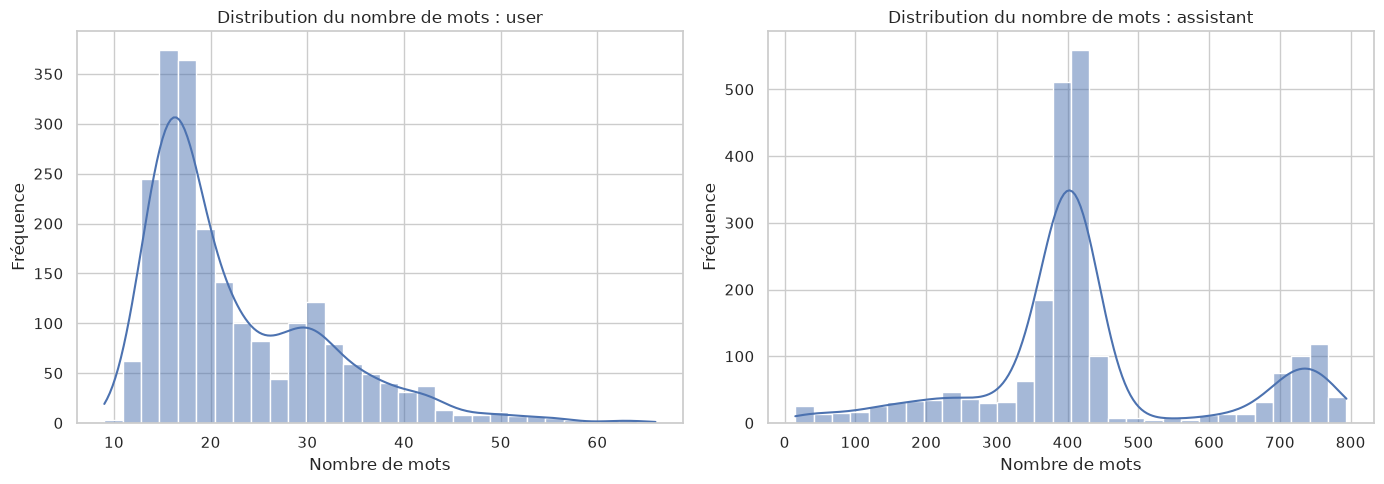

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, TEXT_COLS):
    sns.histplot(data=df_clean, x=f"{col}_word_count", bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution du nombre de mots : {col}")
    ax.set_xlabel("Nombre de mots")
    ax.set_ylabel("Fréquence")
plt.tight_layout()
plt.show()

## 6. Prétraitement NLP (spaCy)

* Les **termes techniques** (`C++`, `AES-256`, `HTTP/2`, `Node.js`, `ssl/tls`…) sont masqués avant spaCy puis restaurés,
  pour ne pas être découpés ni lemmatisés.
* Deux versions sont produites, **traitées à l'identique pour `user` et `assistant`** : `*_clean` (lemmes, stop words
  conservés) et `*_analysis` (lemmes, stop words spaCy supprimés).
* Pour le topic modeling, `user_topic` est dérivée de `user_analysis` en retirant automatiquement les mots présents dans
  plus de `AUTO_MAX_DF` des requêtes **et** sur-représentés côté `user` par rapport à `assistant` (`AUTO_BIAS_Z`).
  Ce filtre alimente le LDA et le graphe NPMI.

In [8]:
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
print("Modèle chargé :", nlp.meta["name"])

Modèle chargé : core_web_sm


In [9]:
# Termes techniques à protéger : amélioration de la regex pour capturer les tirets multiples (ex: AES-256-GCM, CVE-2023-1234)
technical_pattern = re.compile(
    r'\b[A-Za-z0-9]+(?:[-_/.][A-Za-z0-9]+)+\b|'  # Captures complexes : AES-256-GCM, SSL/TLS, Node.js, C++
    r'\b[A-Za-z]*\d+[A-Za-z0-9]*\b|'              # Mots contenant des chiffres (sha256, wpa2)
    r'\b[C|c]\+\+\b|\b[C|c]#\b'                   # C++ et C#
)

# Chargement des stop words spaCy
ALL_STOPWORDS = set(nlp.Defaults.stop_words)
print(f"[{len(ALL_STOPWORDS)}] stop words spaCy")

[326] stop words spaCy


In [10]:
def mask_technical_terms(text):
    """Remplace chaque terme technique par un jeton neutre ; renvoie (texte masqué, table de restauration)."""
    store = {}
    def repl(match):
        key = f"zztechterm{len(store)}zz"
        store[key] = match.group(0).lower()
        return f" {key} "
    return technical_pattern.sub(repl, text), store

def fix_lemma_dynamically(token):
    """Règle algorithmique pure sans liste statique pour corriger les erreurs de lemmatisation de spaCy."""
    lemma = token.lemma_.lower()
    text_lower = token.text.lower()
    
    # Correction des faux pluriels : 'vulnerabilities' -> spaCy sort 'vulnerabilitie' -> corrigé en 'vulnerability'
    if text_lower.endswith("ies") and lemma.endswith("ie"):
        lemma = lemma[:-2] + "y"
        
    # Correction des faux lemmes en -ing : 'phishing' -> spaCy sort 'phishe' -> corrigé en 'phish'
    elif text_lower.endswith("ing") and lemma.endswith("e") and not text_lower.startswith(lemma[:-1]):
        if text_lower[:-3] == lemma[:-1]:
            lemma = text_lower[:-3]
            
    return lemma

def preprocess_text_spacy(texts, remove_stopwords=False):
    """Lemmatise une série de textes en meintenant la protection des termes techniques."""
    masked_stores = [mask_technical_terms(t) for t in texts.fillna("").astype(str)]
    masked = [m[0] for m in masked_stores]
    stores = [m[1] for m in masked_stores]
    
    corpus_out = []
    for doc, store in zip(nlp.pipe(masked, batch_size=128), stores):
        tokens = []
        for token in doc:
            if token.is_space or token.is_punct:
                continue
                
            key = token.text.lower()
            if key in store:
                # Terme technique restauré tel quel (ex: aes-256-gcm)
                tokens.append(store[key])
                continue
                
            # Lemmatisation corrigée dynamiquement
            lemma = fix_lemma_dynamically(token)
            
            if remove_stopwords and (token.is_stop or lemma in ALL_STOPWORDS):
                continue
                
            if len(lemma) >= 2:
                tokens.append(lemma)
                
        corpus_out.append(" ".join(tokens))
    return corpus_out

In [11]:
for col in TEXT_COLS:
    df_clean[f"{col}_clean"] = preprocess_text_spacy(df_clean[col], remove_stopwords=False)
    df_clean[f"{col}_analysis"] = preprocess_text_spacy(df_clean[col], remove_stopwords=True)
    df_clean[f"{col}_word_count_clean"] = df_clean[f"{col}_clean"].str.split().str.len()
    df_clean[f"{col}_word_count_analysis"] = df_clean[f"{col}_analysis"].str.split().str.len()

print("Colonnes *_clean et *_analysis créées.")
display(df_clean[["user", "user_clean", "user_analysis"]].head(3))

Colonnes *_clean et *_analysis créées.


,user,user_clean,user_analysis
0,Explain the fundamental data flow of a Reflect...,explain the fundamental datum flow of reflect ...,explain fundamental datum flow reflect xss att...
1,How does a Reflected XSS vulnerability in an A...,how do reflect xss vulnerability in an api end...,reflect xss vulnerability api endpoint return ...
2,"What is ""DOM Clobbering"" and how can it be use...",what be dom clobbering and how can it be use t...,dom clobbering escalate enable reflected xss p...


In [12]:
# user_analysis reste traité comme assistant_analysis (spaCy seul) : les deux colonnes restent comparables.
# Le filtre statistique alimente une colonne séparée, user_topic, réservée au LDA et au NPMI.
n = len(df_clean)

def doc_freq(series):
    return Counter(w for t in series for w in set(t.split()))

df_u = doc_freq(df_clean["user_analysis"])
print("Top 5 df user_analysis :", [(w, round(c / n, 3)) for w, c in df_u.most_common(5)])
df_a = doc_freq(df_clean["assistant_analysis"])

freq = pd.DataFrame({"mot": list(df_u)})
freq["df_user"] = freq["mot"].map(df_u) / n
freq["df_assistant"] = freq["mot"].map(df_a).fillna(0) / n

# Sur-représentation côté user : log2 du rapport des fréquences documentaires (lissé),
# standardisée par médiane / MAD sur les mots assez fréquents pour être fiables
eps = 1 / n
freq["bias"] = np.log2((freq["df_user"] + eps) / (freq["df_assistant"] + eps))
ref = freq.loc[freq["df_user"] * n >= MIN_DF, "bias"]
med = ref.median()
mad = (ref - med).abs().median() * 1.4826
freq["bias_z"] = (freq["bias"] - med) / (mad if mad > 0 else 1.0)

freq["auto_stop"] = (freq["df_user"] > AUTO_MAX_DF) & (freq["bias_z"] > AUTO_BIAS_Z)
AUTO_STOPWORDS = set(freq.loc[freq["auto_stop"], "mot"])

candidates = freq[freq["df_user"] > AUTO_MAX_DF].sort_values("df_user", ascending=False)
if candidates.empty:
    print("⚠️ Aucun mot au-dessus du seuil : user_analysis est peut-être déjà filtrée "
          "(relancer le prétraitement spaCy) ou AUTO_MAX_DF est trop haut.")
print(f"{len(candidates)} mots avec df_user > {AUTO_MAX_DF:.0%} | écartés (sur-représentés côté user) : {len(AUTO_STOPWORDS)}")
display(candidates.round(3))

df_clean["user_topic"] = df_clean["user_analysis"].apply(
    lambda t: " ".join(w for w in t.split() if w not in AUTO_STOPWORDS))

Top 5 df user_analysis : [('implement', 0.205), ('attack', 0.196), ('explain', 0.172), ('exploit', 0.149), ('implementation', 0.133)]
11 mots avec df_user > 10% | écartés (sur-représentés côté user) : 1


,mot,df_user,df_assistant,bias,bias_z,auto_stop
305,implement,0.205,0.530,-1.368,0.658,False
26,attack,0.196,0.715,-1.861,0.370,False
1,explain,0.172,0.062,1.464,2.317,True
7,exploit,0.149,0.504,-1.749,0.435,False
309,implementation,0.133,0.245,-0.882,0.943,False
40,vulnerability,0.130,0.516,-1.981,0.299,False
74,technique,0.123,0.608,-2.306,0.109,False
19,include,0.115,0.528,-2.196,0.174,False
58,bypass,0.111,0.275,-1.302,0.697,False
102,perform,0.111,0.377,-1.757,0.431,False


In [13]:
rows = []
for col in TEXT_COLS:
    for label, c in [("Brut", f"{col}_word_count"),
                     ("Lemmatisé (stop words conservés)", f"{col}_word_count_clean"),
                     ("Analyse (sans stop words)", f"{col}_word_count_analysis")]:
        rows.append({"Colonne": col, "Version": label,
                     "Moyenne": df_clean[c].mean(), "Médiane": df_clean[c].median()})
display(pd.DataFrame(rows).round(2))

,Colonne,Version,Moyenne,Médiane
0,user,Brut,22.54,19.0
1,user,Lemmatisé (stop words conservés),22.14,19.0
2,user,Analyse (sans stop words),13.98,12.0
3,assistant,Brut,429.27,404.0
4,assistant,Lemmatisé (stop words conservés),423.91,400.0
5,assistant,Analyse (sans stop words),250.99,236.0


## 7. Mots les plus fréquents

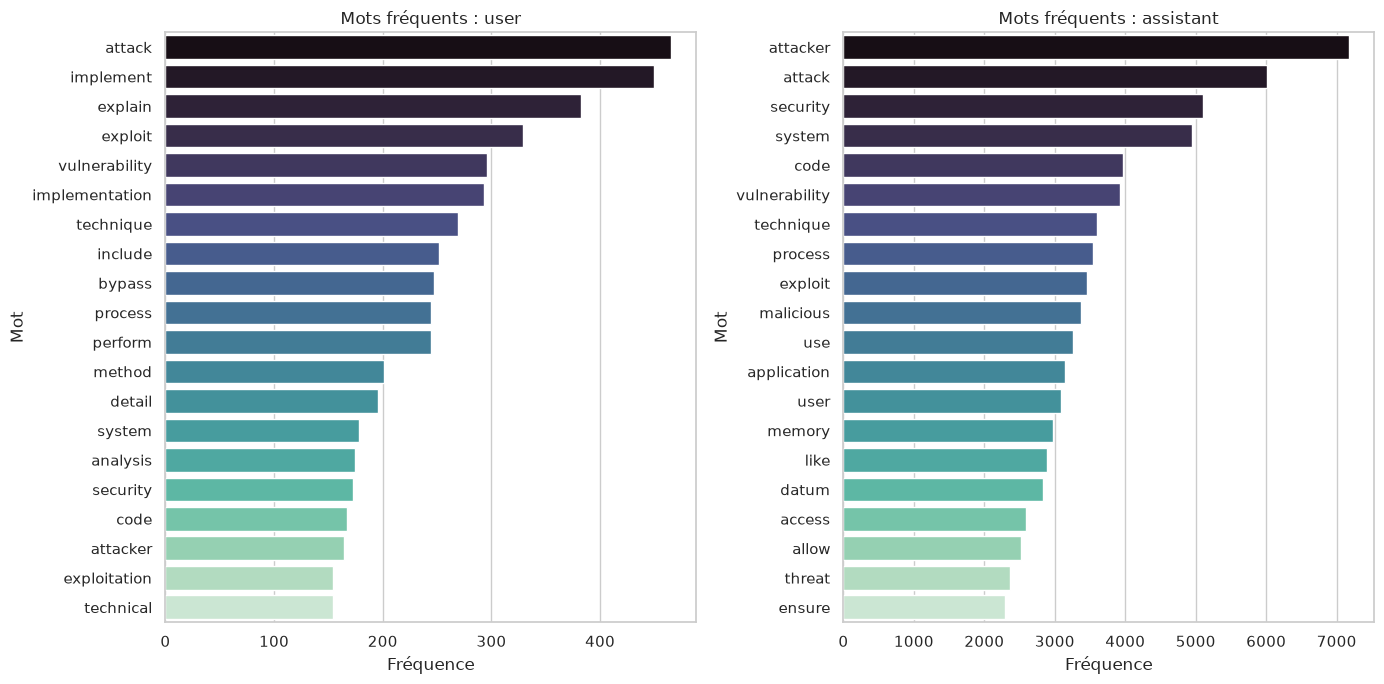

In [14]:
analysis_columns = [f"{c}_analysis" for c in TEXT_COLS]
top_words = {}
for col in analysis_columns:
    counts = Counter(" ".join(df_clean[col]).split())
    top_words[col] = counts.most_common(20)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, title in zip(axes, analysis_columns, ["Mots fréquents : user", "Mots fréquents : assistant"]):
    temp = pd.DataFrame(top_words[col], columns=["Mot", "Fréquence"])
    sns.barplot(data=temp, x="Fréquence", y="Mot", hue="Mot", palette="mako", legend=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 8. Modélisation de thèmes (LDA)

Le LDA est appliqué à la colonne **`user_analysis`** (les requêtes décrivent le sujet).
Le corpus est construit de façon à rester **aligné ligne à ligne** avec le DataFrame.

### 8.1 Corpus et choix du nombre de thèmes k

In [15]:
# Documents non vides uniquement, en gardant l'index de df_clean
df_lda = df_clean.loc[df_clean["user_topic"].str.strip().ne("")].copy()
docs_user = [t.split() for t in df_lda["user_topic"]]      # réutilisé pour le graphe NPMI (section 9)

dictionary = corpora.Dictionary(docs_user)
dictionary.filter_extremes(no_below=MIN_DF, no_above=1.0)   # max_df déjà appliqué en amont (section 6)
corpus = [dictionary.doc2bow(d) for d in docs_user]

# Documents devenus vides après filtrage du dictionnaire : on les écarte ensemble (docs, corpus, df_lda)
keep = [i for i, bow in enumerate(corpus) if bow]
dropped = len(corpus) - len(keep)
df_lda = df_lda.iloc[keep].copy()
docs = [docs_user[i] for i in keep]
corpus = [corpus[i] for i in keep]
print(f"Documents LDA : {len(corpus)} (écartés : {dropped}) | Vocabulaire : {len(dictionary)} mots")

Documents LDA : 2194 (écartés : 0) | Vocabulaire : 1093 mots


Calcul des scores de cohérence C_V...


k =  4 | C_V = 0.2140


k =  5 | C_V = 0.2427


k =  6 | C_V = 0.2750


k =  7 | C_V = 0.2749


k =  8 | C_V = 0.2691


k =  9 | C_V = 0.2754


k = 10 | C_V = 0.2808


k = 11 | C_V = 0.2632


k = 12 | C_V = 0.2875

Meilleur k selon C_V : 12 | k retenu (BEST_K) : 12


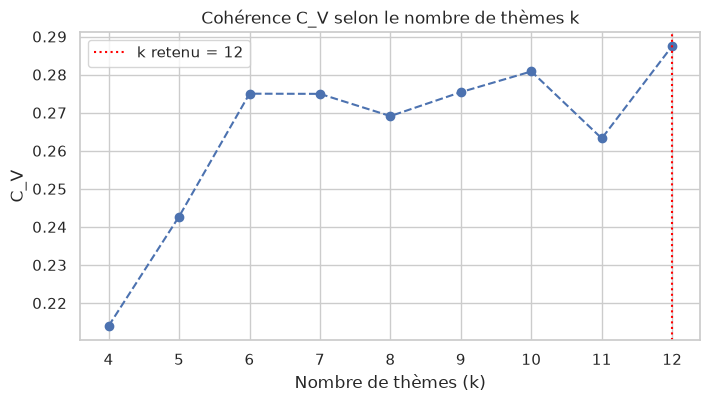

In [16]:
coherence_scores = []
print("Calcul des scores de cohérence C_V...")
for k in K_RANGE:
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     passes=LDA_PASSES, random_state=RANDOM_STATE)
    cm = CoherenceModel(model=model, texts=docs, dictionary=dictionary, coherence="c_v", processes=1)
    coherence_scores.append(cm.get_coherence())
    print(f"k = {k:2d} | C_V = {coherence_scores[-1]:.4f}")

k_best_coherence = list(K_RANGE)[int(np.argmax(coherence_scores))]
BEST_K = K_OVERRIDE if K_OVERRIDE is not None else k_best_coherence
print(f"\nMeilleur k selon C_V : {k_best_coherence} | k retenu (BEST_K) : {BEST_K}")

plt.figure(figsize=(8, 4))
plt.plot(list(K_RANGE), coherence_scores, marker="o", linestyle="--")
plt.axvline(BEST_K, color="red", linestyle=":", label=f"k retenu = {BEST_K}")
plt.title("Cohérence C_V selon le nombre de thèmes k")
plt.xlabel("Nombre de thèmes (k)")
plt.ylabel("C_V")
plt.legend()
plt.grid(True)
plt.show()

   > **Choix de k** : `BEST_K` vaut par défaut le k qui maximise C_V ; pour un autre k, renseigne `K_OVERRIDE` en section 1.

### 8.2 Modèle final et nommage des thèmes

In [17]:
lda_final = LdaModel(corpus=corpus, id2word=dictionary, num_topics=BEST_K,
                     passes=LDA_PASSES, random_state=RANDOM_STATE)

print("=== MOTS-CLÉS DE CHAQUE THÈME ===")
for topic_id in range(BEST_K):
    terms = [t for t, _ in lda_final.show_topic(topic_id, topn=8)]
    print(f"Thème {topic_id} : {', '.join(terms)}")

=== MOTS-CLÉS DE CHAQUE THÈME ===
Thème 0 : code, network, injection, implement, atombombing, lorawan, zigbee, frame
Thème 1 : attack, implement, session, attacker, capture, request, emanation, design
Thème 2 : detection, implement, evade, hijacking, dll, windows, technique, implementation
Thème 3 : construct, pattern, spoof, model, attack, ppid, develop, process
Thème 4 : attack, researcher, implement, bypass, methodology, develop, implementation, boot
Thème 5 : module, implement, method, privilege, stomping, technique, bypass, chain
Thème 6 : api, syscall, build, process, manipulation, gate, heaven, private
Thème 7 : attack, exploit, implementation, detail, vulnerability, rsa, key, signature
Thème 8 : implement, attack, fault, analysis, key, technique, extract, operation
Thème 9 : process, identify, detect, creation, practical, event, pattern, detection
Thème 10 : vulnerability, application, exploit, describe, attacker, bypass, e.g, xss
Thème 11 : researcher, analysis, communication,

In [18]:
# Nommage automatique et reproductible : les 3 mots-clés dominants de chaque thème.
# (Un nommage manuel peut remplacer ces libellés après lecture de la cellule précédente.)
topic_names = {
    topic_id: " / ".join(term for term, _ in lda_final.show_topic(topic_id, topn=3))
    for topic_id in range(BEST_K)
}

def topic_label(topic_id):
    return f"T{topic_id} · {topic_names[topic_id]}"

pd.Series({topic_label(t): ", ".join(w for w, _ in lda_final.show_topic(t, topn=8)) for t in range(BEST_K)},
          name="mots-clés").to_frame()

,mots-clés
T0 · code / network / injection,"code, network, injection, implement, atombombi..."
T1 · attack / implement / session,"attack, implement, session, attacker, capture,..."
T2 · detection / implement / evade,"detection, implement, evade, hijacking, dll, w..."
T3 · construct / pattern / spoof,"construct, pattern, spoof, model, attack, ppid..."
T4 · attack / researcher / implement,"attack, researcher, implement, bypass, methodo..."
T5 · module / implement / method,"module, implement, method, privilege, stomping..."
T6 · api / syscall / build,"api, syscall, build, process, manipulation, ga..."
T7 · attack / exploit / implementation,"attack, exploit, implementation, detail, vulne..."
T8 · implement / attack / fault,"implement, attack, fault, analysis, key, techn..."
T9 · process / identify / detect,"process, identify, detect, creation, practical..."


### 8.3 Visualisation et répartition des thèmes

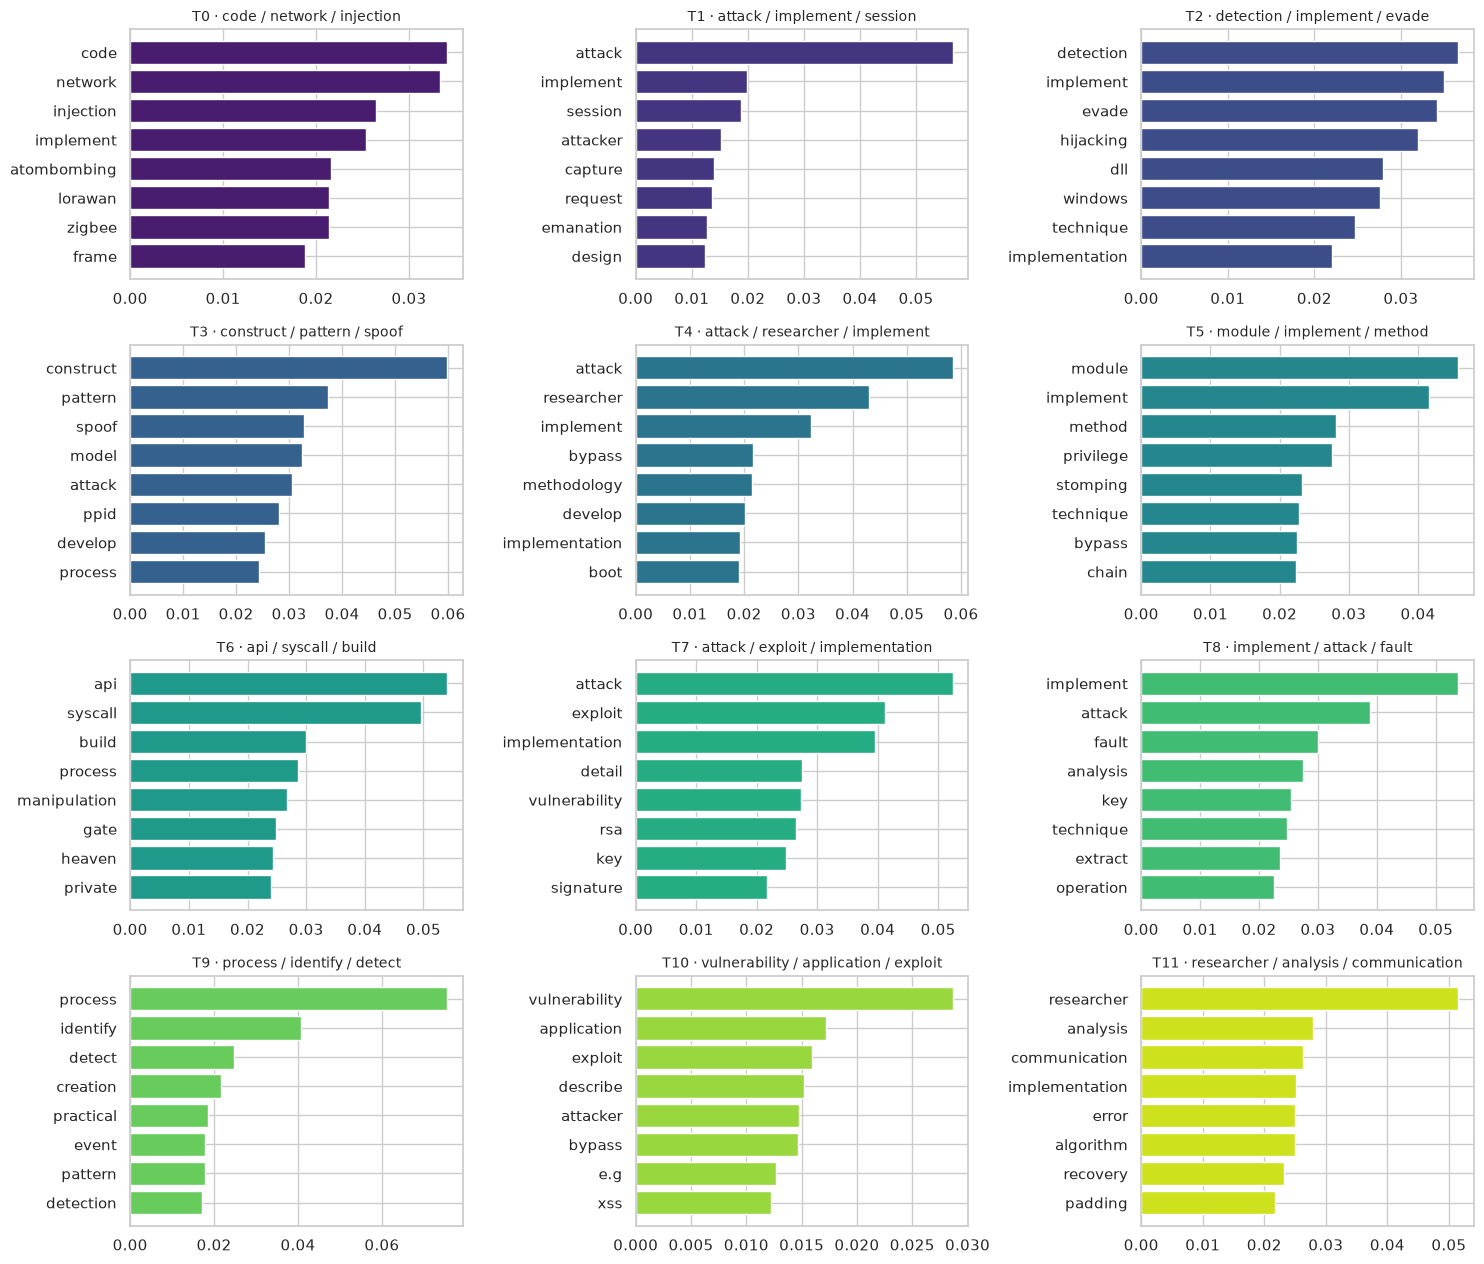

In [19]:
# Poids des 8 termes principaux de chaque thème (version statique, lisible sur GitHub)
ncols = 3
nrows = math.ceil(BEST_K / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2 * nrows), squeeze=False)
for topic_id, ax in zip(range(BEST_K), axes.ravel()):
    terms = lda_final.show_topic(topic_id, topn=8)[::-1]
    ax.barh([t for t, _ in terms], [w for _, w in terms], color=sns.color_palette("viridis", BEST_K)[topic_id])
    ax.set_title(topic_label(topic_id), fontsize=10)
for ax in axes.ravel()[BEST_K:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

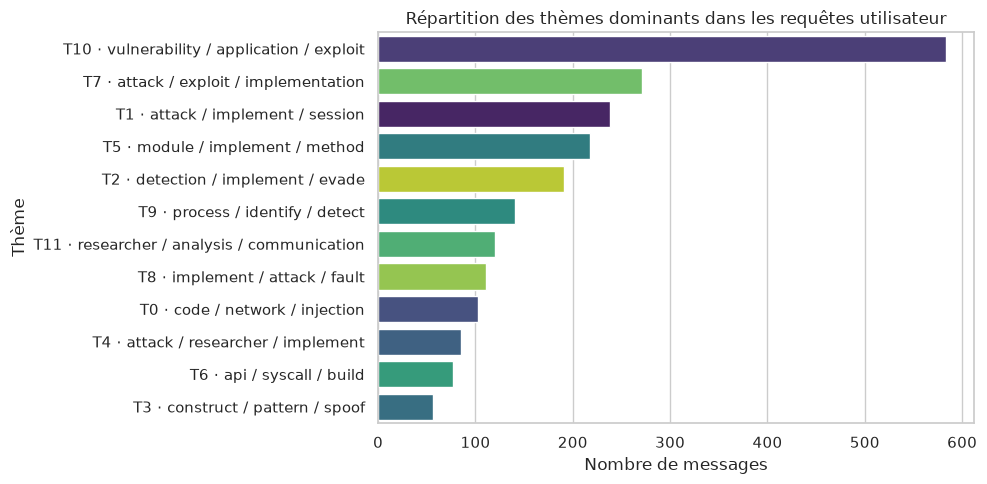

In [20]:
dominant = []
for bow in corpus:
    probs = lda_final.get_document_topics(bow, minimum_probability=0)
    dominant.append(topic_label(max(probs, key=lambda x: x[1])[0]))
df_lda["dominant_topic"] = dominant
df_clean["dominant_topic"] = df_lda["dominant_topic"]        # alignement par index (NaN pour les lignes écartées)

plt.figure(figsize=(10, 5))
sns.countplot(data=df_lda, y="dominant_topic", order=df_lda["dominant_topic"].value_counts().index,
              hue="dominant_topic", palette="viridis", legend=False)
plt.title("Répartition des thèmes dominants dans les requêtes utilisateur")
plt.xlabel("Nombre de messages")
plt.ylabel("Thème")
plt.tight_layout()
plt.show()

> **Lecture.** La cohérence C_V reste **faible** (0,21 → 0,29) et croît encore à k = 12, borne haute de la recherche : les thèmes sont surtout portés par des verbes génériques des consignes (« implement », « attack », « explain » n'est filtré qu'automatiquement). Les thèmes sont donc des **pseudo-labels bruités** : utiles pour structurer l'exploration et pour le Notebook 2B, mais pas des catégories métier. Un thème domine (T10, vulnérabilités applicatives, ~27 % des requêtes).

## 9. Co-occurrence des mots : NPMI et communautés Louvain

NPMI(a, b) = PMI(a, b) / −log₂ P(a, b), bornée dans [−1, 1]. Les probabilités marginales sont calculées sur les
mêmes paires que P(a, b). Les paires **non observées** (ou vues moins de `NPMI_MIN_COOC` fois) valent `NaN`
(et non 0, qui signifierait « indépendants »).

### 9.1 Calcul de la matrice NPMI et construction du graphe

In [21]:
def compute_npmi(docs, top_n=150, window=5, min_cooc=5):
    """Renvoie (npmi_df, cooc_df, word_counts). NaN = paire non observée ou trop rare."""
    wc = Counter(w for d in docs for w in d)
    vocab = [w for w, _ in wc.most_common(top_n)]
    idx = {w: i for i, w in enumerate(vocab)}
    n = len(vocab)

    cooc = np.zeros((n, n), dtype=np.int64)
    for d in docs:
        for i, w in enumerate(d):
            a = idx.get(w)
            if a is None:
                continue
            for v in d[i + 1:i + 1 + window]:
                b = idx.get(v)
                if b is None or b == a:
                    continue
                cooc[a, b] += 1
                cooc[b, a] += 1

    total_pairs = cooc.sum()
    p_ab = cooc / total_pairs
    p_a = cooc.sum(axis=1) / total_pairs
    with np.errstate(divide="ignore", invalid="ignore"):
        npmi = np.log2(p_ab / np.outer(p_a, p_a)) / (-np.log2(p_ab))
    npmi[cooc < min_cooc] = np.nan
    np.fill_diagonal(npmi, np.nan)

    return (pd.DataFrame(npmi, index=vocab, columns=vocab),
            pd.DataFrame(cooc, index=vocab, columns=vocab),
            wc)


def build_graph_npmi(npmi_df, cooc_df, wc, min_npmi=0.2):
    """Graphe pondéré par la NPMI (arêtes >= min_npmi) + communautés de Louvain (triées par taille)."""
    words = npmi_df.index.tolist()
    values = npmi_df.values
    G = nx.Graph()
    for i, a in enumerate(words):
        for j in range(i + 1, len(words)):
            val = values[i, j]
            if not np.isnan(val) and val >= min_npmi:
                G.add_edge(a, words[j], weight=float(val), count=int(cooc_df.iat[i, j]))

    if G.number_of_nodes() == 0:
        raise ValueError("Graphe vide : baisse NPMI_QUANTILE ou NPMI_MIN_COOC.")

    for node in G.nodes:
        G.nodes[node]["freq"] = int(wc[node])

    communities = sorted(nx.algorithms.community.louvain_communities(G, weight="weight", seed=RANDOM_STATE),
                         key=len, reverse=True)
    for cid, members in enumerate(communities):
        for w in members:
            G.nodes[w]["community"] = cid
    return G, communities

In [22]:
npmi_df, cooc_df, word_counts = compute_npmi(docs_user, NPMI_TOP_N, NPMI_WINDOW, NPMI_MIN_COOC)
npmi_threshold = float(np.nanquantile(npmi_df.values, NPMI_QUANTILE))
print(f"Seuil NPMI retenu (quantile {NPMI_QUANTILE:.0%}) : {npmi_threshold:.3f}")
G, communities = build_graph_npmi(npmi_df, cooc_df, word_counts, npmi_threshold)

print(f"Graphe NPMI | Nœuds : {G.number_of_nodes()} | Arêtes : {G.number_of_edges()} | "
      f"Communautés : {len(communities)}")
print("Tailles des communautés :", [len(c) for c in communities])

Seuil NPMI retenu (quantile 90%) : 0.202
Graphe NPMI | Nœuds : 130 | Arêtes : 137 | Communautés : 21
Tailles des communautés : [17, 13, 11, 11, 11, 10, 9, 8, 6, 5, 4, 4, 3, 3, 3, 2, 2, 2, 2, 2, 2]


### 9.2 Top des associations

In [23]:
pairs = [(a, b, d["weight"], d["count"]) for a, b, d in G.edges(data=True)]
top_pairs = (pd.DataFrame(pairs, columns=["mot_1", "mot_2", "NPMI", "co-occurrences"])
             .sort_values("NPMI", ascending=False).head(20).round(2).reset_index(drop=True))
display(top_pairs)

,mot_1,mot_2,NPMI,co-occurrences
0,privilege,escalation,0.54,51
1,provide,example,0.48,32
2,detail,technical,0.47,110
3,dll,hijacking,0.46,30
4,iot,device,0.42,18
5,comprehensive,methodology,0.42,30
6,mathematical,model,0.39,12
7,control,flow,0.39,31
8,key,extract,0.38,21
9,architecture,trust,0.38,8


### 9.3 Graphe statique

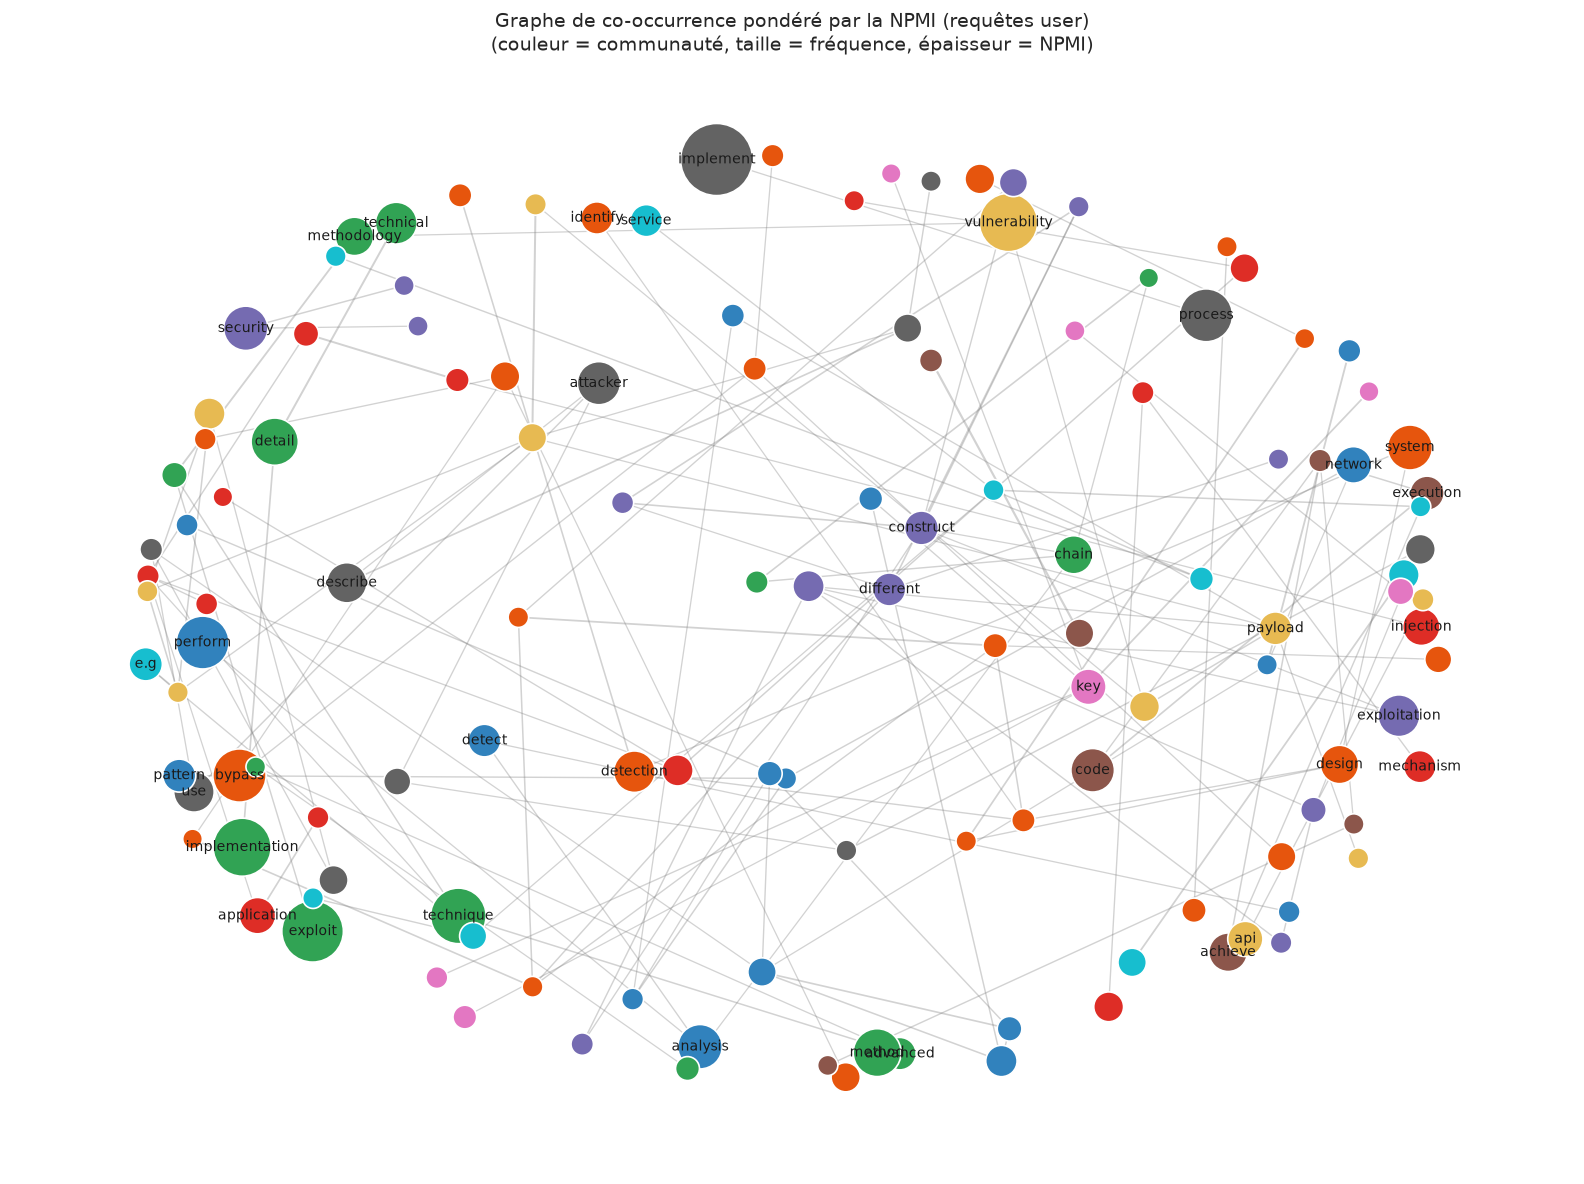

In [24]:
def plot_npmi_graph(G, figsize=(16, 12), label_top=40):
    pos = nx.spring_layout(G, k=0.6, seed=RANDOM_STATE, weight="weight")
    freqs = np.array([G.nodes[n]["freq"] for n in G.nodes])
    sizes = 200 + 2500 * (freqs - freqs.min()) / (freqs.max() - freqs.min() + 1e-9)
    colors = [PALETTE[G.nodes[n]["community"] % len(PALETTE)] for n in G.nodes]
    widths = [0.5 + 2.0 * d["weight"] for _, _, d in G.edges(data=True)]

    fig, ax = plt.subplots(figsize=figsize)
    nx.draw_networkx_edges(G, pos, width=widths, alpha=0.35, edge_color="gray", ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=sizes, node_color=colors,
                           edgecolors="white", linewidths=1.2, ax=ax)
    top_nodes = {n for n, _ in sorted(G.nodes(data="freq"), key=lambda x: -x[1])[:label_top]}
    nx.draw_networkx_labels(G, pos, labels={n: n for n in top_nodes}, font_size=10, ax=ax)
    ax.set_title("Graphe de co-occurrence pondéré par la NPMI (requêtes user)\n"
                 "(couleur = communauté, taille = fréquence, épaisseur = NPMI)", fontsize=14)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_npmi_graph(G)

### 9.4 Heatmap NPMI

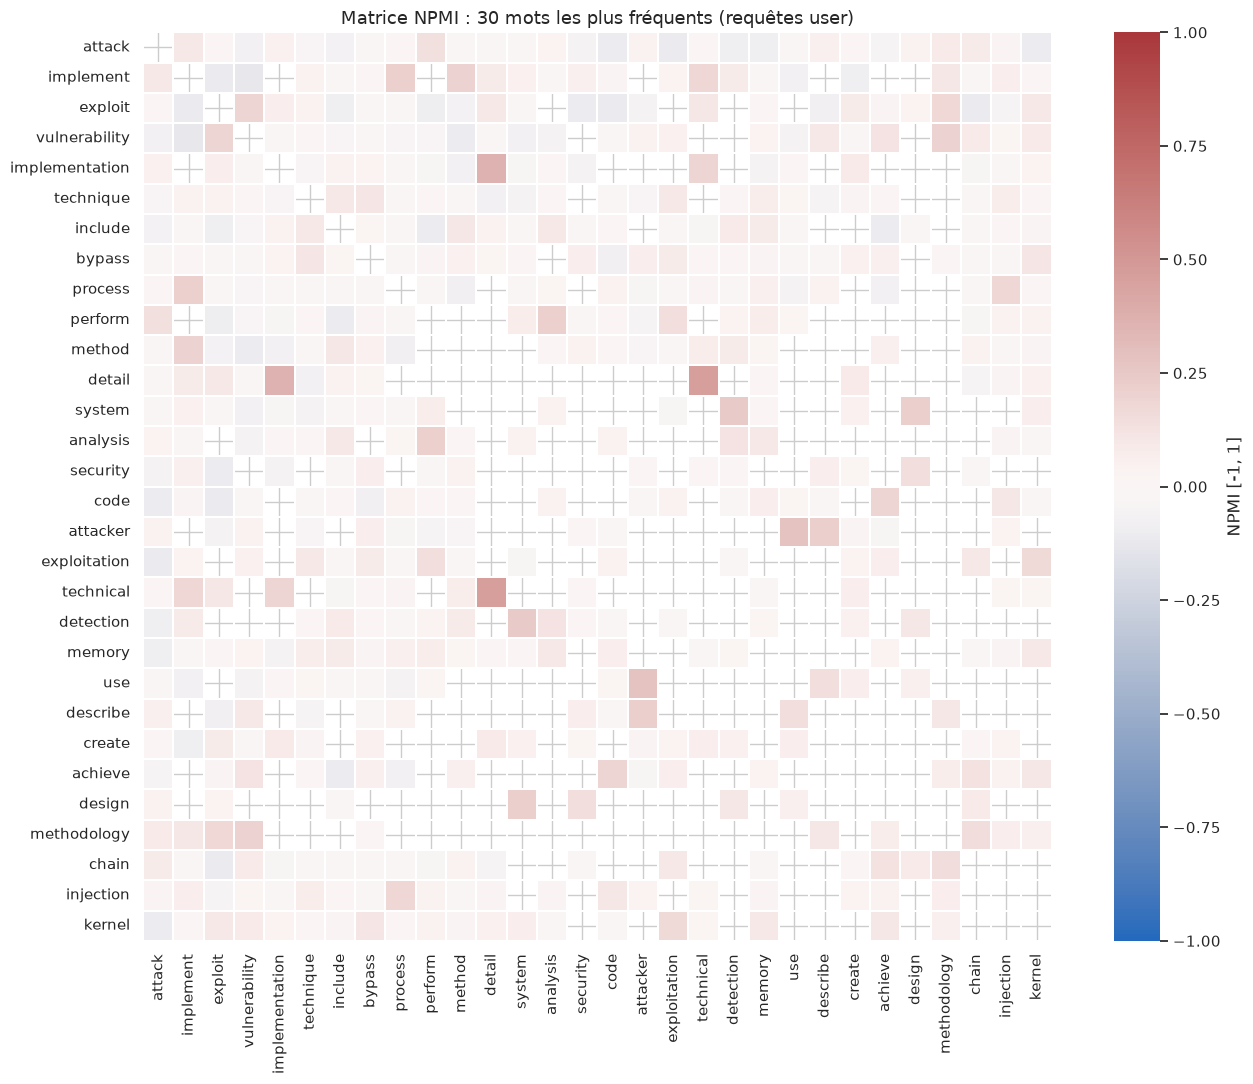

In [25]:
def plot_npmi_heatmap(npmi_df, wc, n_words=30):
    words = [w for w, _ in wc.most_common(n_words) if w in npmi_df.index]
    sub = npmi_df.loc[words, words]
    plt.figure(figsize=(14, 11))
    # Cases blanches = paires non observées / trop rares (NaN), pas « indépendantes »
    sns.heatmap(sub, mask=sub.isna(), cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
                cbar_kws={"label": "NPMI [-1, 1]"}, linewidths=0.3)
    plt.title(f"Matrice NPMI : {len(words)} mots les plus fréquents (requêtes user)", fontsize=13)
    plt.tight_layout()
    plt.show()

plot_npmi_heatmap(npmi_df, word_counts, n_words=30)

### 9.5 Graphe interactif (PyVis)

> **Lecture.** Le graphe de co-occurrence (130 mots, 137 arêtes, 21 communautés de Louvain) retrouve des **expressions techniques stables** : *privilege escalation* (NPMI 0,54), *dll hijacking*, *code execution*, *c2 communication*, *rop gadget*. Plusieurs paires restent des tournures de consigne (*provide example*, *technical detail*), cohérent avec la faiblesse des thèmes LDA.

In [26]:
def build_pyvis_npmi(G, path=FIG_DIR / "npmi_graph.html"):
    net = Network(height="750px", width="100%", bgcolor="#ffffff", font_color="black",
                  directed=False, cdn_resources="remote")
    net.barnes_hut(gravity=-6000, spring_length=140)

    freqs = [d["freq"] for _, d in G.nodes(data=True)]
    fmin, fmax = min(freqs), max(freqs)

    for n, d in G.nodes(data=True):
        size = 12 + 40 * (d["freq"] - fmin) / (fmax - fmin + 1e-9)
        neighbors = sorted(G[n].items(), key=lambda x: -x[1]["weight"])[:5]
        neigh_txt = "<br>".join(f"{m} (NPMI {e['weight']:.2f})" for m, e in neighbors)
        net.add_node(n, label=n, size=size,
                     color=PALETTE[d["community"] % len(PALETTE)],
                     title=(f"<b>{n}</b><br>Fréquence : {d['freq']}<br>"
                            f"Communauté : {d['community']}<br><br><i>Associations fortes :</i><br>{neigh_txt}"))
    for u, v, d in G.edges(data=True):
        net.add_edge(u, v, value=d["weight"], title=f"NPMI = {d['weight']:.2f} | co-occurrences = {d['count']}")

    net.write_html(str(path))
    return os.path.relpath(path, Path.cwd())

html_path = build_pyvis_npmi(G)
display(IFrame(html_path, width="100%", height=770))

## 10. Embeddings (vectorisation)

Deux représentations complémentaires :
* **Sentence-Transformers** : un vecteur par requête `user` (texte brut, car les transformers exploitent la syntaxe
  et les mots vides). Utilisé pour la visualisation, le clustering (comparé au LDA) et la recherche sémantique.
* **Word2Vec** : un vecteur par mot, entraîné sur les textes lemmatisés. Comparé aux communautés NPMI de la section 9.

In [27]:
### 10.1 Embeddings de phrases (Sentence-Transformers)
st_model = SentenceTransformer(EMB_MODEL)

if os.path.exists(EMB_CACHE) and np.load(EMB_CACHE, mmap_mode="r").shape[0] == len(df_clean):
    emb_user = np.load(EMB_CACHE)
    print("Embeddings chargés depuis le cache.")
else:
    emb_user = st_model.encode(
        df_clean["user"].tolist(),
        batch_size=EMB_BATCH,
        show_progress_bar=True,
        normalize_embeddings=True,      # vecteurs unitaires : produit scalaire = similarité cosinus
    )
    np.save(EMB_CACHE, emb_user)

print("Matrice d'embeddings :", emb_user.shape)    # (nb requêtes, 384)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3404.44it/s]

Embeddings chargés depuis le cache.
Matrice d'embeddings : (2194, 384)


/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/.venv/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


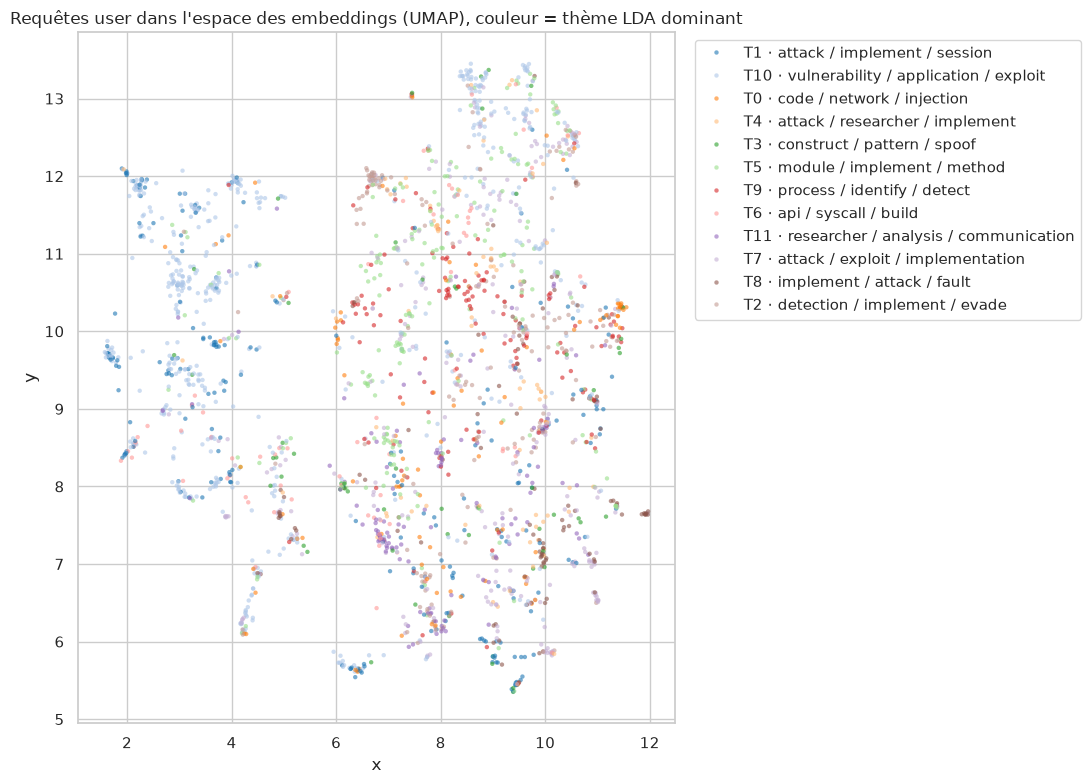

In [28]:
### 10.2 Projection 2D des requêtes
emb_lda = emb_user[df_lda.index.to_numpy()]      # mêmes lignes que le LDA, donc comparable

try:
    import umap
    coords = umap.UMAP(n_components=2, metric="cosine", random_state=RANDOM_STATE).fit_transform(emb_lda)
    method = "UMAP"
except ImportError:
    coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(emb_lda)
    method = "PCA"

plot_df = pd.DataFrame(coords, columns=["x", "y"])
plot_df["thème LDA"] = df_lda["dominant_topic"].values

plt.figure(figsize=(11, 8))
sns.scatterplot(data=plot_df, x="x", y="y", hue="thème LDA", palette="tab20", s=10, alpha=0.6, linewidth=0)
plt.title(f"Requêtes user dans l'espace des embeddings ({method}), couleur = thème LDA dominant")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [29]:
### 10.3 Clustering KMeans sur embeddings et comparaison au LDA
N_CLUSTERS = BEST_K                                # même nombre de groupes que le LDA pour comparer
km = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10).fit(emb_lda)
df_lda["emb_cluster"] = km.labels_

sil = silhouette_score(emb_lda, km.labels_, sample_size=min(5000, len(emb_lda)), random_state=RANDOM_STATE)
ari = adjusted_rand_score(df_lda["dominant_topic"], km.labels_)
print(f"Silhouette : {sil:.3f} | ARI (clusters vs thèmes LDA) : {ari:.3f}")

display(pd.crosstab(df_lda["dominant_topic"], df_lda["emb_cluster"]))

# Requêtes les plus proches du centre de chaque cluster, pour le nommer
for c in range(N_CLUSTERS):
    idx = np.where(km.labels_ == c)[0]
    order = np.linalg.norm(emb_lda[idx] - km.cluster_centers_[c], axis=1).argsort()[:3]
    print(f"\n--- Cluster {c} ({len(idx)} requêtes) ---")
    for t in df_lda["user"].iloc[idx[order]]:
        print("  •", t[:120].replace("\n", " "))

Silhouette : 0.032 | ARI (clusters vs thèmes LDA) : 0.092


emb_cluster,0,1,2,3,4,5,6,7,8,9,10,11
dominant_topic,,,,,,,,,,,,
T0 · code / network / injection,14,20,12,4,9,4,9,0,8,5,13,5
T1 · attack / implement / session,27,19,1,61,16,34,16,0,2,9,49,4
T10 · vulnerability / application / exploit,4,14,27,108,15,142,97,55,10,10,13,88
T11 · researcher / analysis / communication,22,20,0,2,40,1,3,1,0,10,17,4
T2 · detection / implement / evade,23,35,17,0,4,2,3,4,48,36,11,8
T3 · construct / pattern / spoof,3,9,1,0,7,3,9,2,1,0,15,6
T4 · attack / researcher / implement,0,1,3,1,8,3,1,3,21,15,25,4
T5 · module / implement / method,6,8,18,0,30,10,20,4,16,14,13,79
T6 · api / syscall / build,1,1,8,9,14,2,18,1,13,4,2,4



--- Cluster 0 (124 requêtes) ---
  • What are the technical methods for implementing sinkholing and botnet takeover operations for IoT-specific C2 protocols?
  • What are the technical details of implementing encrypted C2 protocols that evade deep packet inspection on IoT networks?
  • Explain how C2 servers implement traffic morphing to mimic legitimate application protocols, including the statistical m

--- Cluster 1 (194 requêtes) ---
  • What are the advanced anti-emulation techniques employed by polymorphic malware to detect and evade automated analysis e
  • Explain how polymorphic malware implements anti-tampering mechanisms using code checksums that update dynamically during
  • How would you perform differential analysis of metamorphic malware families to identify the invariant code portions that

--- Cluster 2 (119 requêtes) ---
  • What are the methods for implementing anti-ROP techniques in compiler toolchains and their effectiveness?
  • How is Return-Oriented Programming

In [30]:
### 10.4 Recherche sémantique vs TF-IDF
def semantic_search(query, top_k=5):
    q = st_model.encode([query], normalize_embeddings=True)
    scores = (emb_user @ q.T).ravel()
    top = np.argsort(-scores)[:top_k]
    return pd.DataFrame({"score": scores[top].round(3), "user": df_clean["user"].iloc[top].str[:150].values})

tfidf = TfidfVectorizer(min_df=MIN_DF)
X_tfidf = tfidf.fit_transform(df_clean["user_clean"])

def tfidf_search(query, top_k=5):
    q = tfidf.transform(preprocess_text_spacy(pd.Series([query])))
    scores = cosine_similarity(q, X_tfidf).ravel()
    top = np.argsort(-scores)[:top_k]
    return pd.DataFrame({"score": scores[top].round(3), "user": df_clean["user"].iloc[top].str[:150].values})

query = "how can I detect ransomware on my network?"
print("=== Embeddings ==="); display(semantic_search(query))
print("=== TF-IDF ===");     display(tfidf_search(query))

=== Embeddings ===


,score,user
0,0.561,Explain how ransomware leverages legitimate Wi...
1,0.556,Explain the implementation of ransomware that ...
2,0.555,How would you design a ransomware detection sy...
3,0.549,What are the advanced anti-forensics technique...
4,0.540,How would you perform dynamic analysis of rans...


=== TF-IDF ===


,score,user
0,0.325,What is the CAN bus arbitration mechanism that...
1,0.305,What is the mathematical framework for calcula...
2,0.289,How is behavioral analysis performed on IoT de...
3,0.279,"What is a ""rootkit""? Explain how a kernel-leve..."
4,0.272,"How is competitive cryptojacking implemented, ..."


In [31]:
### 10.5 Embeddings de mots (Word2Vec) et lien avec le graphe NPMI
w2v_sentences = ([t.split() for t in df_clean["user_analysis"]] +
                 [t.split() for t in df_clean["assistant_analysis"]])

w2v = Word2Vec(sentences=w2v_sentences, vector_size=W2V_DIM, window=W2V_WINDOW,
               min_count=W2V_MIN_COUNT, sg=1, workers=4, epochs=W2V_EPOCHS, seed=RANDOM_STATE)
print("Vocabulaire Word2Vec :", len(w2v.wv))

for w in ["malware", "phishing", "encryption", "firewall", "vulnerability"]:
    if w in w2v.wv:
        print(f"{w:14} →", [(s, round(sc, 2)) for s, sc in w2v.wv.most_similar(w, topn=5)])

Vocabulaire Word2Vec : 5478
malware        → [('family', 0.68), ('rootkit', 0.62), ('author', 0.6), ('polymorphic', 0.59), ('fileless', 0.59)]
phishing       → [('phishe', 0.8), ('email', 0.7), ('spear', 0.7), ('drive-by', 0.67), ('deface', 0.65)]
encryption     → [('encrypt', 0.72), ('aes-256', 0.63), ('cryptographic', 0.62), ('algorithm', 0.62), ('aes-256-gcm', 0.61)]
firewall       → [('ids/ips', 0.7), ('wafs', 0.63), ('egress', 0.59), ('firewalls', 0.59), ('waf', 0.55)]
vulnerability  → [('flaw', 0.86), ('exploit', 0.7), ('bug', 0.65), ('vulnerable', 0.59), ('weakness', 0.59)]


In [32]:
# Part des 5 voisins Word2Vec d'un mot qui sont dans la même communauté NPMI
shares = []
for w in G.nodes:
    if w in w2v.wv:
        neigh = [s for s, _ in w2v.wv.most_similar(w, topn=5) if s in G]
        if neigh:
            shares.append(np.mean([G.nodes[s]["community"] == G.nodes[w]["community"] for s in neigh]))
print(f"Part moyenne de voisins Word2Vec dans la même communauté NPMI : {np.mean(shares):.2%}")

Part moyenne de voisins Word2Vec dans la même communauté NPMI : 47.75%


> **Lecture.** Les clusters KMeans sur embeddings SBERT recoupent peu les thèmes LDA (ARI 0,09) et sont peu séparés (silhouette 0,03) : le corpus est un continuum de sujets techniques plutôt que des groupes nets. Les plus proches voisins Word2Vec sont pertinents (*vulnerability* → *flaw*, *exploit* ; *encryption* → *aes-256-gcm*) et ~48 % d'entre eux tombent dans la même communauté NPMI : les deux représentations capturent en partie la même structure. Sur la requête « detect ransomware », la recherche par embeddings renvoie des questions pertinentes alors que TF-IDF (requête courte, peu de mots communs) se trompe.

## 11. Vectorisation : TF-IDF vs Word2Vec vs GloVe vs SBERT

La section 10 compare les représentations **qualitativement**. On les compare maintenant **sur deux tâches mesurées**, avec le même protocole pour chacune :

| Tâche | Protocole | Métriques |
| --- | --- | --- |
| **A. Recherche** (préfigure le RAG) | Chaque question `user` doit retrouver **sa propre réponse** `assistant` parmi toutes les réponses | Recall@1, Recall@10, MRR@10 |
| **B. Catégorisation** (préfigure le tri SOC) | Régression logistique sur les catégories faibles du Notebook 2A, mots-clés des règles masqués (anti-fuite), validation croisée 5 plis | macro-F1 |

| Représentation | Type (cours) | Construction |
| --- | --- | --- |
| TF-IDF | fréquentielle, creuse | unigrammes + bigrammes, ajustée sur le corpus |
| Word2Vec | dense, statique, **entraînée sur le corpus** | moyenne des vecteurs de mots (section 10.5) |
| GloVe | dense, statique, **pré-entraînée** (Wikipedia + Gigaword, 100 d) | moyenne des vecteurs de mots |
| SBERT | dense, **contextuelle** (Transformer) | `all-MiniLM-L6-v2`, une phrase = un vecteur |

In [33]:
import gensim.downloader as gensim_api
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

from cybersec_nlp.evaluation.metrics import reciprocal_rank
from cybersec_nlp.nlp.classifier import mask_label_keywords, weak_label

glove = gensim_api.load("glove-wiki-gigaword-100")
TOKEN = re.compile(r"[a-z0-9][a-z0-9\-\.]*[a-z0-9]|[a-z0-9]")

def mean_vectors(texts, vectors, dim):
    """Moyenne des vecteurs des mots connus (vecteur nul si aucun mot connu)."""
    out = np.zeros((len(texts), dim), dtype=np.float32)
    for i, text in enumerate(texts):
        words = [w for w in TOKEN.findall(text.lower()) if w in vectors]
        if words:
            out[i] = np.mean([vectors[w] for w in words], axis=0)
    return out

def l2(x):
    x = np.asarray(x, dtype=np.float32)
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-9, None)

queries, answers = df_clean["user"].tolist(), df_clean["assistant"].tolist()
q_lem, a_lem = df_clean["user_analysis"].tolist(), df_clean["assistant_analysis"].tolist()

tfidf_qa = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(answers + queries)
representations = {
    "TF-IDF": (tfidf_qa.transform(queries), tfidf_qa.transform(answers)),
    "Word2Vec (corpus)": (l2(mean_vectors(q_lem, w2v.wv, W2V_DIM)), l2(mean_vectors(a_lem, w2v.wv, W2V_DIM))),
    "GloVe (pré-entraîné)": (l2(mean_vectors(queries, glove, 100)), l2(mean_vectors(answers, glove, 100))),
    "SBERT (contextuel)": (emb_user, st_model.encode(answers, batch_size=EMB_BATCH, normalize_embeddings=True)),
}

rows = []
gold = np.arange(len(queries))
for name, (Q, A) in representations.items():
    sims = cosine_similarity(Q, A)
    ranks = np.argsort(-sims, axis=1)[:, :10]
    rows.append({
        "représentation": name,
        "Recall@1": float(np.mean(ranks[:, 0] == gold)),
        "Recall@10": float(np.mean([g in r for g, r in zip(gold, ranks)])),
        "MRR@10": float(np.mean([reciprocal_rank(list(r), {g}, 10) for g, r in zip(gold, ranks)])),
    })
retrieval_cmp = pd.DataFrame(rows).set_index("représentation").round(3)
display(retrieval_cmp)

,Recall@1,Recall@10,MRR@10
représentation,,,
TF-IDF,0.768,0.912,0.818
Word2Vec (corpus),0.504,0.779,0.597
GloVe (pré-entraîné),0.158,0.325,0.208
SBERT (contextuel),0.707,0.888,0.770


1585 documents étiquetés, 7 catégories


,Recall@1,Recall@10,MRR@10,macro-F1 (5 plis)
représentation,,,,
TF-IDF,0.768,0.912,0.818,0.560
Word2Vec (corpus),0.504,0.779,0.597,0.496
GloVe (pré-entraîné),0.158,0.325,0.208,0.230
SBERT (contextuel),0.707,0.888,0.770,0.486


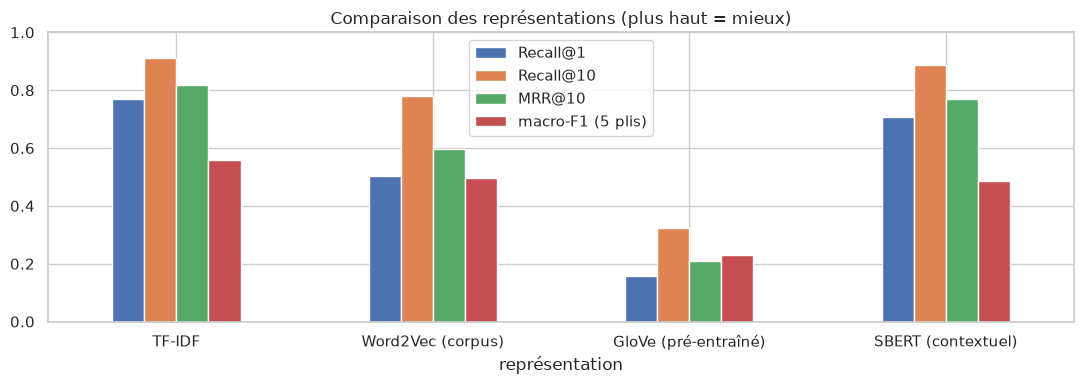

In [34]:
# Tâche B : catégories faibles (règles du Notebook 2A) ; les mots-clés des règles sont masqués
labels = df_clean["user"].map(weak_label)
mask = labels.notna() & labels.map(labels.value_counts()).ge(40)
texts_b = (df_clean.loc[mask, "user"] + " " + df_clean.loc[mask, "assistant"]).map(mask_label_keywords).tolist()
y_b = labels[mask].to_numpy()
print(f"{mask.sum()} documents étiquetés, {len(set(y_b))} catégories")

features_b = {
    "TF-IDF": TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts_b),
    "Word2Vec (corpus)": l2(mean_vectors(texts_b, w2v.wv, W2V_DIM)),
    "GloVe (pré-entraîné)": l2(mean_vectors(texts_b, glove, 100)),
    "SBERT (contextuel)": st_model.encode(texts_b, batch_size=EMB_BATCH, normalize_embeddings=True),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
classif_cmp = pd.Series({
    name: cross_val_score(LogisticRegression(max_iter=3000, class_weight="balanced"), X, y_b,
                          cv=cv, scoring="f1_macro").mean()
    for name, X in features_b.items()
}, name="macro-F1 (5 plis)").round(3)

vector_cmp = retrieval_cmp.join(classif_cmp)
display(vector_cmp)
vector_cmp.plot.bar(rot=0, figsize=(11, 4), title="Comparaison des représentations (plus haut = mieux)")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

> **Lecture.** **TF-IDF gagne les deux tâches** : Recall@1 = 0,77 en recherche question → réponse et macro-F1 = 0,56 en catégorisation. Les questions et leurs réponses partagent beaucoup de termes techniques rares, que TF-IDF pondère fortement. SBERT suit de près en recherche (0,71) mais perd en catégorisation (0,49) une fois les mots-clés masqués. Word2Vec entraîné sur le corpus fait mieux que GloVe (0,50 vs 0,16 en Recall@1) : GloVe, appris sur Wikipedia, ignore le vocabulaire cyber. **Conséquences** : les baselines « texte seul » de l'équipe utilisent TF-IDF ; la branche dense du RAG (Notebook 4A) utilise un encodeur **multilingue** (E5), indispensable pour les questions des analystes posées en français sur un corpus anglais, cas où TF-IDF ne retrouve rien.

## 12. NER cyber : extraction des IP, CVE, malwares, logiciels et cibles

### 12.1 Extracteur à règles aligné sur STIX 2.1

`cybersec_nlp.nlp.ner.CyberNER` combine des **expressions régulières validées** (IPv4 via `ipaddress`, CVE, identifiants ATT&CK `T####`, empreintes MD5/SHA-1/SHA-256) et des **lexiques** (malwares, outils, acteurs, logiciels, vecteurs d'attaque, secteurs ciblés), avec des alias français (« rançongiciel » → *ransomware*) pour relier les questions des analystes au corpus anglais. En cas de chevauchement, le span le plus long gagne.

| Label | Type STIX 2.1 | | Label | Type STIX 2.1 |
| --- | --- | --- | --- | --- |
| `IP` | ipv4-addr / indicator | | `MALWARE` | malware |
| `CVE` | vulnerability | | `TOOL` | tool |
| `ATTACK_ID` | attack-pattern (ATT&CK) | | `THREAT_ACTOR` | threat-actor |
| `HASH` | file hashes / indicator | | `SOFTWARE` | software |
| `VECTOR` | attack-pattern (nommé) | | `TARGET` | identity (secteur) |

In [35]:
from cybersec_nlp.nlp.ner import GAZETTEER, CyberNER

ner = CyberNER()
doc_entities = {
    row.doc_id: ner.extract(row.user) + ner.extract(row.assistant) for row in df_clean.itertuples()
}
mentions = Counter(e.label for ents in doc_entities.values() for e in ents)
distinct = {lab: len({e.key for ents in doc_entities.values() for e in ents if e.label == lab}) for lab in mentions}
coverage = pd.DataFrame({"mentions": mentions, "entités distinctes": distinct}).sort_values("mentions", ascending=False)
display(coverage)
print(f"Documents avec au moins une entité : {sum(bool(v) for v in doc_entities.values())} / {len(doc_entities)}")

example = next(r for r in df_clean.itertuples() if len({e.label for e in doc_entities[r.doc_id]}) >= 4)
print("\nExemple —", example.doc_id, ":", example.user[:160])
display(pd.DataFrame([(e.text, e.label, e.key) for e in doc_entities[example.doc_id]], columns=["texte", "label", "clé"]))

,mentions,entités distinctes
SOFTWARE,5821,60
VECTOR,4648,46
TARGET,579,18
TOOL,517,27
MALWARE,221,27
ATTACK_ID,171,85
CVE,140,86
IP,81,19
THREAT_ACTOR,32,10
HASH,3,1


Documents avec au moins une entité : 1813 / 2194

Exemple — HF-00153 : How can an XXE vulnerability be leveraged to perform Server-Side Request Forgery (SSRF)? Explain the mechanism and provide a payload that forces the server to m


,texte,label,clé
0,XXE,VECTOR,xxe
1,SSRF,VECTOR,ssrf
2,HTTP,SOFTWARE,http
3,http,SOFTWARE,http
4,169.254.169.254,IP,169.254.169.254
5,XXE,VECTOR,xxe
6,xxe,VECTOR,xxe
7,http,SOFTWARE,http
8,169.254.169.254,IP,169.254.169.254
9,xxe,VECTOR,xxe


### 12.2 Fine-tuning de SecBERT (classification de tokens)

Un lexique ne reconnaît que ce qu'il contient. Pour généraliser, on **fine-tune SecBERT** (`jackaduma/SecBERT`, BERT pré-entraîné sur des textes de cybersécurité) en étiquetage de séquence **BIO**, avec une supervision *silver* : les étiquettes de l'extracteur à règles.

**Protocole anti-circularité** — évaluer SecBERT contre les étiquettes qui ont servi à l'entraîner ne prouverait rien. On retire donc **20 % des termes du lexique** (tirés au hasard par label) de l'entraînement : toute phrase qui en contient est exclue du train et de la validation. Au test, on mesure :

* **F1 par entité** (span et label exacts) sur les phrases de test, contre les étiquettes silver ;
* **rappel sur entités inconnues** : part des mentions des termes retirés que SecBERT retrouve. L'extracteur à règles privé de ces termes obtient **0 %** par construction : tout point gagné est de la généralisation.

Le découpage train / validation / test (70 / 15 / 15) se fait **par document**, pour qu'une même réponse ne soit pas des deux côtés.

In [36]:
import random

import torch
from torch.utils.data import Dataset as TorchDataset
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

rng = random.Random(RANDOM_STATE)
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")

# Termes du lexique effectivement présents dans le corpus, puis tirage des termes « inconnus »
present = {(e.label, e.key) for ents in doc_entities.values() for e in ents if e.label in GAZETTEER}
holdout = set()
for label in GAZETTEER:
    terms = sorted(k for lab, k in present if lab == label)
    holdout |= {(label, t) for t in rng.sample(terms, max(1, round(NER_HOLDOUT_FRACTION * len(terms))))}
holdout_keys = {k for _, k in holdout}
print(f"{len(holdout)} termes retirés de l'entraînement, ex. :", sorted(holdout_keys)[:12])

doc_ids = df_clean["doc_id"].tolist()
rng.shuffle(doc_ids)
n_tr, n_va = int(0.70 * len(doc_ids)), int(0.85 * len(doc_ids))
split_of = {d: ("train" if i < n_tr else "val" if i < n_va else "test") for i, d in enumerate(doc_ids)}

sentences = {"train": [], "val": [], "test": []}
for row in df_clean.itertuples():
    for field in (row.user, row.assistant):
        for sentence in SENTENCE_SPLIT.split(field):
            if 3 <= len(sentence.split()) <= 80:
                ents = ner.extract(sentence)
                has_holdout = any(e.key in holdout_keys for e in ents)
                split = split_of[row.doc_id]
                if split != "test" and has_holdout:
                    continue
                if split != "test" and not ents and rng.random() > 0.15:
                    continue          # sous-échantillonne les phrases sans entité (classe O majoritaire)
                sentences[split].append((sentence, ents))
print({k: len(v) for k, v in sentences.items()})

37 termes retirés de l'entraînement, ex. : ['android', 'apache', 'apt10', 'arp spoofing', 'bash', 'blackenergy', 'darkside', 'drive-by download', 'e-commerce', 'elasticsearch', 'exchange', 'financial sector']


{'train': 9157, 'val': 1845, 'test': 6714}


In [37]:
from cybersec_nlp.nlp.ner import LABELS as NER_LABELS

TAGS = ["O"] + [f"{p}-{lab}" for lab in NER_LABELS for p in ("B", "I")]
tag2id = {t: i for i, t in enumerate(TAGS)}
tokenizer = AutoTokenizer.from_pretrained(NER_BASE_MODEL)

def encode(sentence, ents):
    enc = tokenizer(sentence, truncation=True, max_length=NER_MAX_LEN, return_offsets_mapping=True)
    labels = []
    for start, end in enc.pop("offset_mapping"):
        if start == end:
            labels.append(-100)                       # tokens spéciaux ignorés par la loss
            continue
        tag = "O"
        for e in ents:
            if start >= e.start and end <= e.end:
                tag = ("B-" if start == e.start else "I-") + e.label
        labels.append(tag2id[tag])
    enc["labels"] = labels
    return enc

class NERDataset(TorchDataset):
    def __init__(self, items):
        self.items = [encode(s, e) for s, e in items]
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        return self.items[i]

datasets_ner = {k: NERDataset(v) for k, v in sentences.items()}
model_ner = AutoModelForTokenClassification.from_pretrained(
    NER_BASE_MODEL, num_labels=len(TAGS), id2label=dict(enumerate(TAGS)), label2id=tag2id)

args = TrainingArguments(
    output_dir=str(OUT_DIR / "ner_runs"), num_train_epochs=NER_EPOCHS, learning_rate=5e-5,
    per_device_train_batch_size=NER_BATCH, per_device_eval_batch_size=64, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="no", logging_strategy="epoch", report_to=[],
    fp16=torch.cuda.is_available(), seed=RANDOM_STATE,
)
trainer = Trainer(model=model_ner, args=args, train_dataset=datasets_ner["train"],
                  eval_dataset=datasets_ner["val"], data_collator=DataCollatorForTokenClassification(tokenizer))
train_output = trainer.train()
history = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h or "eval_loss" in h])
display(history[["epoch"] + [c for c in ("loss", "eval_loss") if c in history]].groupby("epoch").first().round(4))

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 101/101 [00:00<00:00, 3439.66it/s]


[transformers] BertForTokenClassification LOAD REPORT from: jackaduma/SecBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,0.105438,0.021298
2,0.004597,0.014679
3,0.001460,0.015281


,loss,eval_loss
epoch,,
1.0,0.1054,0.0213
2.0,0.0046,0.0147
3.0,0.0015,0.0153


In [38]:
def predict_spans(sentence):
    """Spans (début, fin, label) prédits par SecBERT, reconstruits à partir des tags BIO."""
    enc = tokenizer(sentence, truncation=True, max_length=NER_MAX_LEN, return_offsets_mapping=True, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0].tolist()
    with torch.no_grad():
        pred = model_ner(**{k: v.to(model_ner.device) for k, v in enc.items()}).logits.argmax(-1)[0].tolist()
    spans, current = [], None
    for (start, end), tag_id in zip(offsets, pred):
        if start == end:
            continue
        tag = TAGS[tag_id]
        if tag.startswith("B-") or (tag.startswith("I-") and (current is None or current[2] != tag[2:])):
            if current:
                spans.append(tuple(current))
            current = [start, end, tag[2:]]
        elif tag.startswith("I-") and current:
            current[1] = end
        else:
            if current:
                spans.append(tuple(current))
            current = None
    if current:
        spans.append(tuple(current))
    return set(spans)

model_ner.eval()
tp, fp, fn = Counter(), Counter(), Counter()
unseen_total = unseen_found = 0
for sentence, ents in sentences["test"]:
    gold = {(e.start, e.end, e.label) for e in ents}
    pred = predict_spans(sentence)
    for s in pred & gold: tp[s[2]] += 1
    for s in pred - gold: fp[s[2]] += 1
    for s in gold - pred: fn[s[2]] += 1
    for e in ents:
        if e.key in holdout_keys:
            unseen_total += 1
            unseen_found += (e.start, e.end, e.label) in pred

def prf(t, p, n):
    precision = t / (t + p) if t + p else 0.0
    recall = t / (t + n) if t + n else 0.0
    return precision, recall, (2 * precision * recall / (precision + recall) if precision + recall else 0.0)

ner_rows = [{"label": lab, "support": tp[lab] + fn[lab], **dict(zip(("précision", "rappel", "F1"), prf(tp[lab], fp[lab], fn[lab])))}
            for lab in NER_LABELS if tp[lab] + fn[lab] > 0]
micro = prf(sum(tp.values()), sum(fp.values()), sum(fn.values()))
ner_report = pd.DataFrame(ner_rows).set_index("label").round(3)
display(ner_report)
ner_metrics = {"micro_precision": micro[0], "micro_recall": micro[1], "micro_f1": micro[2],
               "macro_f1": float(ner_report["F1"].mean()),
               "unseen_entity_recall": unseen_found / unseen_total if unseen_total else float("nan"),
               "unseen_mentions": unseen_total, "rule_based_unseen_recall": 0.0}
print({k: round(v, 3) if isinstance(v, float) else v for k, v in ner_metrics.items()})

model_ner.save_pretrained(OUT_DIR / "ner_secbert")
tokenizer.save_pretrained(OUT_DIR / "ner_secbert")

,support,précision,rappel,F1
label,,,,
CVE,26,0.733,0.846,0.786
IP,4,0.571,1.000,0.727
ATTACK_ID,28,0.833,0.893,0.862
THREAT_ACTOR,9,0.000,0.000,0.000
MALWARE,27,0.826,0.704,0.760
TOOL,86,0.955,0.744,0.837
VECTOR,675,0.906,0.911,0.908
TARGET,55,0.717,0.691,0.704
SOFTWARE,1025,0.966,0.924,0.945


{'micro_precision': 0.928, 'micro_recall': 0.896, 'micro_f1': 0.912, 'macro_f1': 0.725, 'unseen_entity_recall': 0.257, 'unseen_mentions': 210, 'rule_based_unseen_recall': 0.0}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.10it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.09it/s]

('/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/artifacts/notebook1/ner_secbert/tokenizer_config.json',
 '/home/magreyuptown/Projects/cybersec-NLP-GraphRAG-QA/artifacts/notebook1/ner_secbert/tokenizer.json')

In [39]:
demo = "The LockBit ransomware gang exploited CVE-2023-4966 in Citrix NetScaler to target hospitals, beaconing to 185.220.101.5."
print("Règles  :", [(e.text, e.label) for e in ner.extract(demo)])
print("SecBERT :", sorted((demo[s:e], lab) for s, e, lab in predict_spans(demo)))

Règles  : [('LockBit', 'MALWARE'), ('ransomware', 'VECTOR'), ('CVE-2023-4966', 'CVE'), ('Citrix', 'SOFTWARE'), ('hospitals', 'TARGET'), ('185.220.101.5', 'IP')]
SecBERT : [('.', 'IP'), ('.5', 'IP'), ('CVE-2023-4966', 'CVE')]


> **Lecture.** SecBERT reproduit l'extracteur à règles avec un **micro-F1 de 0,91** (précision 0,93, rappel 0,90) et un macro-F1 de 0,73, et retrouve **26 % des mentions d'entités qu'il n'a jamais vues étiquetées** (210 mentions de 37 termes retirés), là où les règles privées de ces termes sont à 0 % : le modèle généralise au-delà du lexique. Les labels fréquents et contextuels sont bien appris (SOFTWARE 0,95, VECTOR 0,91, ATTACK_ID 0,86) ; les labels rares échouent : THREAT_ACTOR (32 mentions dans tout le corpus) n'est jamais prédit et les IP (81 mentions) sont mal délimitées, comme le montre l'exemple (fragments « . » et « .5 »). **Décision** : le graphe et le MVP utilisent l'extracteur à règles (déterministe, explicable, IP et CVE validées par regex) ; SecBERT est livré dans `artifacts/notebook1/ner_secbert` pour enrichir les lexiques. Les scores étant mesurés contre des étiquettes *silver*, une annotation manuelle d'un échantillon reste nécessaire.

## 13. Ontologie STIX 2.1 / MITRE ATT&CK et graphe de connaissances

```
(Document)-[:MENTIONS]->(Indicator | Vulnerability | AttackPattern | Malware | Tool | ThreatActor | Software | Target)
(ThreatActor)-[:USES]->(Malware | Tool | AttackPattern)       (Malware)-[:USES]->(AttackPattern)
(ThreatActor | Malware | AttackPattern)-[:TARGETS]->(Target)   (AttackPattern)-[:TARGETS]->(Software)
(Malware)-[:EXPLOITS]->(Vulnerability)                         (Vulnerability)-[:AFFECTS]->(Software)
(Indicator)-[:INDICATES]->(Malware | ThreatActor)
```

* `MENTIONS` est **factuel** : l'entité apparaît dans le document (provenance `doc_id`).
* Les relations typées (vocabulaire STIX : *uses*, *targets*, *exploits*, *indicates* ; *affects* est une extension) sont des **candidates** : deux entités co-occurrent dans la **même phrase**. Chaque arête porte `method`, `weight` (nombre de documents) et `doc_ids` (preuves). Elles ne sont jamais présentées comme des faits validés.
* Chaque arête porte une **provenance** (`source`), exploitée par l'audit d'empoisonnement du Notebook 4B.

In [40]:
from cybersec_nlp.graph.knowledge_graph import build_knowledge_graph, graph_summary

kg = build_knowledge_graph(df_clean[["doc_id", "raw_index", "user", "assistant"]], ner)
summary_kg = graph_summary(kg)
display(pd.DataFrame({"nœuds": pd.Series(summary_kg["nodes"])}), pd.DataFrame({"arêtes": pd.Series(summary_kg["edges"])}))

typed = [e for e in kg.edges if e.rel != "MENTIONS"]
top_rel = pd.DataFrame([{
    "source": kg.nodes[e.src].name, "type source": kg.nodes[e.src].label, "relation": e.rel,
    "cible": kg.nodes[e.dst].name, "type cible": kg.nodes[e.dst].label,
    "documents": e.props["weight"], "preuves": ", ".join(e.props["doc_ids"][:3]),
} for e in sorted(typed, key=lambda e: -e.props["weight"])[:15]])
display(top_rel)

hubs = pd.DataFrame([(n.label, n.name, n.props["doc_count"]) for n in kg.nodes.values() if n.label != "Document"],
                    columns=["type", "entité", "documents"]).sort_values("documents", ascending=False)
display(hubs.head(10))

,nœuds
Document,2194
AttackPattern,131
Software,60
Tool,27
Target,18
Indicator,20
Vulnerability,86
Malware,27
ThreatActor,10


,arêtes
MENTIONS,4926
TARGETS,258
USES,38
AFFECTS,55


,source,type source,relation,cible,type cible,documents,preuves
0,privilege escalation,AttackPattern,TARGETS,windows,Software,28,"HF-00696, HF-00857, HF-01010"
1,xss,AttackPattern,TARGETS,http,Software,21,"HF-00006, HF-00008, HF-00009"
2,golden ticket,AttackPattern,TARGETS,kerberos,Software,12,"HF-00512, HF-00514, HF-01451"
3,dll hijacking,AttackPattern,TARGETS,windows,Software,11,"HF-01347, HF-01390, HF-01392"
4,privilege escalation,AttackPattern,TARGETS,linux,Software,11,"HF-00696, HF-01359, HF-01365"
5,ssrf,AttackPattern,TARGETS,http,Software,10,"HF-00189, HF-00190, HF-00196"
6,xxe,AttackPattern,TARGETS,http,Software,9,"HF-00153, HF-00160, HF-00161"
7,csrf,AttackPattern,TARGETS,http,Software,8,"HF-00121, HF-00122, HF-00123"
8,cross-site scripting,AttackPattern,TARGETS,http,Software,7,"HF-00008, HF-00009, HF-00361"
9,sql injection,AttackPattern,TARGETS,http,Software,7,"HF-00061, HF-00067, HF-00074"


,type,entité,documents
16,Software,windows,458
2,Software,http,365
33,AttackPattern,privilege escalation,229
9,AttackPattern,phishing,134
0,AttackPattern,xss,133
140,AttackPattern,buffer overflow,133
147,AttackPattern,side-channel,106
3,AttackPattern,cross-site scripting,106
14,Software,tls,103
21,AttackPattern,remote code execution,96


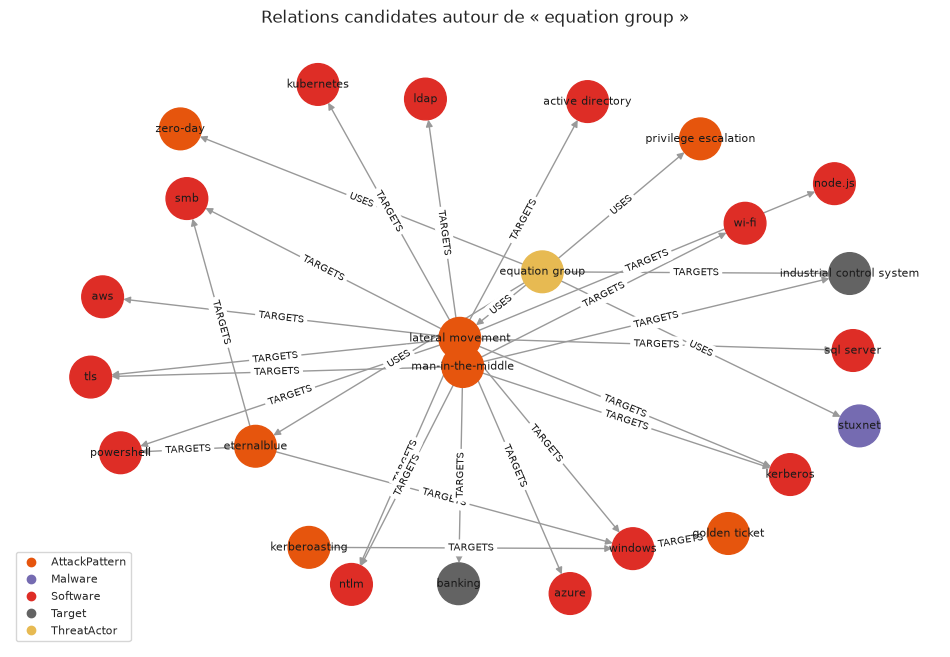

In [41]:
# Sous-graphe autour d'un acteur de la menace : relations typées à 1 saut
center = max((n for n in kg.nodes.values() if n.label == "ThreatActor"), key=lambda n: n.props["doc_count"])
sub = nx.DiGraph()
for e in typed:
    if center.id in (e.src, e.dst):
        sub.add_edge(kg.nodes[e.src].name, kg.nodes[e.dst].name, rel=e.rel, w=e.props["weight"])
for e in typed:   # 2e saut : relations des voisins directs, pour donner du contexte
    s, d = kg.nodes[e.src].name, kg.nodes[e.dst].name
    if (s in sub or d in sub) and sub.number_of_edges() < 30:
        sub.add_edge(s, d, rel=e.rel, w=e.props["weight"])
label_of = {n.name: n.label for n in kg.nodes.values()}
palette = dict(zip(sorted(set(label_of.values())), PALETTE))
pos = nx.spring_layout(sub, seed=RANDOM_STATE, k=1.2)
plt.figure(figsize=(12, 8))
nx.draw_networkx(sub, pos, node_color=[palette[label_of[n]] for n in sub], node_size=900, font_size=8, edge_color="0.6", arrows=True)
nx.draw_networkx_edge_labels(sub, pos, edge_labels={(u, v): d["rel"] for u, v, d in sub.edges(data=True)}, font_size=7)
plt.legend(handles=[plt.Line2D([0], [0], marker="o", ls="", color=c, label=l) for l, c in palette.items() if l in {label_of[n] for n in sub}],
           loc="lower left", fontsize=8)
plt.title(f"Relations candidates autour de « {center.name} »"); plt.axis("off"); plt.show()

> **Lecture.** Le graphe compte **2 573 nœuds** (2 194 documents, 379 entités) et **5 277 arêtes**, dont 4 926 `MENTIONS` factuelles et 351 relations candidates (258 `TARGETS`, 55 `AFFECTS`, 38 `USES`). Les relations les plus soutenues sont plausibles : *privilege escalation → windows* (28 documents), *golden ticket → kerberos*, *xss → http*. Les **hubs** (*windows* : 458 documents, *http* : 365) relient beaucoup de documents sans rapport : le RAG les ignore sauf combinaison avec d'autres entités, et le Notebook 2B les filtre. Les requêtes d'exemple (section 14) montrent que le graphe répond à des questions relationnelles qu'une recherche plein texte traite mal (malwares associés au secteur bancaire, techniques de WannaCry).

## 14. Ingestion Neo4j : scripts Cypher et requêtes analyste

Deux modes d'import, même résultat :

1. **Script** `data/processed/neo4j/import.cypher` — contraintes d'unicité puis lots `UNWIND … MERGE`, **idempotent** (rejouable sans doublons) : `cypher-shell -u neo4j -p <mot de passe> -f data/processed/neo4j/import.cypher`.
2. **Python** `cybersec_nlp.graph.neo4j_loader.load_into_neo4j` — requêtes **paramétrées** (les valeurs ne sont jamais concaténées dans le Cypher ; les labels sont vérifiés contre le schéma). Activé si `NEO4J_URI`, `NEO4J_USERNAME` et `NEO4J_PASSWORD` sont définis.

`data/processed/neo4j/queries.cypher` contient les requêtes d'analyse SOC. Sans serveur Neo4j, on exécute les mêmes motifs sur le graphe en mémoire (`InMemoryGraph`, sous-ensemble Cypher en lecture seule).

In [42]:
from cybersec_nlp.graph.knowledge_graph import export_neo4j_scripts
from cybersec_nlp.graph.neo4j_loader import load_into_neo4j, neo4j_settings

import_path, queries_path = export_neo4j_scripts(kg, config.NEO4J_DIR)
script = import_path.read_text(encoding="utf-8")
print(f"{import_path.relative_to(ROOT)} : {len(script) / 1e6:.2f} Mo, {script.count(chr(10))} instructions")
print("\n".join(script.splitlines()[:12])[:1500], "\n...")

settings = neo4j_settings()
if settings:
    print("Import Neo4j :", load_into_neo4j(kg, settings))
else:
    print("\nNEO4J_* non défini : import Neo4j sauté (le script ci-dessus reste utilisable avec cypher-shell).")

data/processed/neo4j/import.cypher : 1.23 Mo, 50 instructions
// Generated by cybersec_nlp.graph.knowledge_graph — STIX 2.1 aligned schema

CREATE CONSTRAINT attackpattern_name IF NOT EXISTS FOR (n:AttackPattern) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT document_name IF NOT EXISTS FOR (n:Document) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT indicator_name IF NOT EXISTS FOR (n:Indicator) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT malware_name IF NOT EXISTS FOR (n:Malware) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT software_name IF NOT EXISTS FOR (n:Software) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT target_name IF NOT EXISTS FOR (n:Target) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT threatactor_name IF NOT EXISTS FOR (n:ThreatActor) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT tool_name IF NOT EXISTS FOR (n:Tool) REQUIRE n.name IS UNIQUE;
CREATE CONSTRAINT vulnerability_name IF NOT EXISTS FOR (n:Vulnerability) REQUIRE n.name IS UNIQUE;
 
...

NEO4J_* non défini : import Neo4j saut

In [43]:
examples = {
    "Logiciels affectés par CVE-2021-44228": "MATCH (v:Vulnerability {name: 'CVE-2021-44228'})-[:AFFECTS]->(s:Software) RETURN s.name",
    "Malwares associés au secteur bancaire": "MATCH (m:Malware)-[:TARGETS]->(t:Target {name: 'banking'}) RETURN m.name",
    "Techniques utilisées par WannaCry": "MATCH (m:Malware {name: 'wannacry'})-[:USES]->(p:AttackPattern) RETURN p.name",
    "Documents mentionnant mimikatz": "MATCH (d:Document)-[:MENTIONS]->(t:Tool {name: 'mimikatz'}) RETURN d.name LIMIT 5",
}
for title, query in examples.items():
    rows = kg.run(query)
    values = [list(r.values())[0] for r in rows]
    print(f"{title:<40} {query}\n{'':<40} → {values[:8]}")

Logiciels affectés par CVE-2021-44228    MATCH (v:Vulnerability {name: 'CVE-2021-44228'})-[:AFFECTS]->(s:Software) RETURN s.name
                                         → ['log4j']
Malwares associés au secteur bancaire    MATCH (m:Malware)-[:TARGETS]->(t:Target {name: 'banking'}) RETURN m.name
                                         → ['dridex', 'emotet', 'icedid', 'revil', 'sodinokibi', 'trickbot', 'wannacry', 'zeus']
Techniques utilisées par WannaCry        MATCH (m:Malware {name: 'wannacry'})-[:USES]->(p:AttackPattern) RETURN p.name
                                         → ['eternalblue', 'privilege escalation', 'ransomware']
Documents mentionnant mimikatz           MATCH (d:Document)-[:MENTIONS]->(t:Tool {name: 'mimikatz'}) RETURN d.name LIMIT 5
                                         → ['HF-00501', 'HF-00502', 'HF-00504', 'HF-00505', 'HF-00506']


## 15. Livrables pour l'équipe (Jalon 1)

| Fichier (`data/processed/`) | Contenu | Utilisé par |
| --- | --- | --- |
| `corpus_clean.parquet` | corpus nettoyé avec `doc_id` | tous |
| `entities.json` | entités par document (texte, label, offsets, clé canonique, champ) | 2A, 2B, 4B |
| `knowledge_graph.json` | graphe STIX (nœuds, arêtes, provenance) | 4A, 4B, MVP |
| `rag_documents.jsonl` | contrat RAG `doc_id, text, source, title` | 4A, MVP |
| `df_clean_eda.parquet` | thème LDA dominant par question | 2B (pseudo-labels) |
| `neo4j/import.cypher`, `neo4j/queries.cypher` | import et requêtes Neo4j | équipe, soutenance |

In [44]:
from cybersec_nlp.graph.knowledge_graph import extract_corpus_entities, save_graph
from cybersec_nlp.pipelines.build_knowledge_base import rag_documents, write_jsonl

corpus_out = df_clean[["doc_id", "raw_index", "user", "assistant"]]
corpus_out.to_parquet(config.CORPUS_CLEAN, index=False)
config.ENTITIES_JSON.write_text(json.dumps(extract_corpus_entities(corpus_out, ner), ensure_ascii=False), encoding="utf-8")
save_graph(kg, config.KNOWLEDGE_GRAPH_JSON)
write_jsonl(rag_documents(corpus_out), config.RAG_DOCUMENTS)
df_clean[["doc_id", "user", "dominant_topic"]].dropna().to_parquet(config.TOPICS_PARQUET, index=False)

notebook1_metrics = {
    "cleaning": recap.set_index("Étape")["Lignes"].to_dict(),
    "lda": {"k": int(BEST_K), "coherence_cv": float(max(coherence_scores)), "topics": {int(k): v for k, v in topic_names.items()}},
    "npmi_graph": {"nodes": G.number_of_nodes(), "edges": G.number_of_edges(), "communities": len(communities)},
    "embeddings": {"silhouette": float(sil), "ari_vs_lda": float(ari)},
    "vectorisation": vector_cmp.reset_index().to_dict(orient="records"),
    "ner": ner_metrics,
    "graph": summary_kg,
}
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
(config.METRICS_DIR / "notebook1_metrics.json").write_text(json.dumps(notebook1_metrics, indent=2, ensure_ascii=False, default=float))
for path in (config.CORPUS_CLEAN, config.ENTITIES_JSON, config.KNOWLEDGE_GRAPH_JSON, config.RAG_DOCUMENTS,
             config.TOPICS_PARQUET, import_path, queries_path, config.METRICS_DIR / "notebook1_metrics.json"):
    print(f"{path.relative_to(ROOT)!s:<50} {path.stat().st_size / 1e3:>9.1f} Ko")

data/processed/corpus_clean.parquet                   3456.5 Ko
data/processed/entities.json                          1426.1 Ko
data/processed/knowledge_graph.json                   1481.3 Ko
data/processed/rag_documents.jsonl                    7183.6 Ko
data/processed/df_clean_eda.parquet                    187.0 Ko
data/processed/neo4j/import.cypher                    1234.5 Ko
data/processed/neo4j/queries.cypher                      1.3 Ko
reports/metrics/notebook1_metrics.json                   2.4 Ko


## 16. Conclusion

* **Données** : 2 194 documents propres et traçables (`doc_id` stable), révision du dataset figée et vérifiée par SHA-256.
* **Représentations** : TF-IDF est la meilleure baseline sur ce corpus anglais ; un encodeur dense multilingue est retenu pour le RAG (questions en français).
* **NER** : extracteur à règles aligné STIX 2.1 (10 types, alias français, pluriels) + SecBERT fine-tuné (micro-F1 0,91 vs silver, 26 % de rappel sur entités inconnues).
* **Graphe** : ontologie STIX 2.1 / ATT&CK, provenance sur chaque arête, script Neo4j idempotent et loader paramétré, requêtes analyste.
* **Livrables Jalon 1** : `entities.json`, `knowledge_graph.json`, `rag_documents.jsonl`, `df_clean_eda.parquet`, scripts Cypher — consommés par les Notebooks 2A, 2B, 4A, 4B et le MVP.
* **Limites** : corpus pédagogique (peu d'IOC réels, acteurs rares), thèmes LDA génériques, relations typées issues de co-occurrences (non validées), absence d'annotation manuelle pour le NER.
* **Pistes** : annoter 100–200 phrases pour évaluer le NER sans biais ; ajouter un corpus CTI narratif (rapports, MITRE ATT&CK STIX) pour des relations validées.